# HW3: human, AI or fusion text classification

## Setup

In [ ]:
import os

COMPETITION = 'ai-generated-text-detection-hw3-ucu-ai-2026'
SMOKE_TEST = False  # small experiment samples to check every step; EDA always uses all rows
RUNS = os.path.abspath('outputs/runs-smoke' if SMOKE_TEST else 'outputs/runs')
SEED = 42
N_FOLDS = 5
VAL_FOLD = 0
TRAIN_SAMPLE = 50_000
VAL_SAMPLE = 10_000
SEARCH_SAMPLE = 15_000
SEARCH_FOLDS = 3
OOF_FOLDS = 5
FULL_TRAIN = True  # OOF features and final models on all train folds instead of TRAIN_SAMPLE
FIT_ROWS = 100_000  # row cap for each TF-IDF model fit (about 1.5 GB per 10k rows)
FORCE = False  # recompute every cached step (a step whose parameters changed is recomputed anyway)
N_JOBS = 4
RUN_PERPLEXITY = True  # Qwen2.5-0.5B (open weights): 91 GPU min on a fresh run, +0.000 in run 1; cached afterwards
LM_NAME = 'Qwen/Qwen2.5-0.5B'
LM_MAX_TOKENS = 1024
LM_BATCH = 8
RUN_ENCODER = True
ENCODER_NAME = 'xlm-roberta-base'
ENCODER_MAX_LEN = 512
ENCODER_EPOCHS = 2
ENCODER_BATCH = 16
ENCODER_LR = 2e-5
# encoder v2: sequence head + per-token "AI-written" head, trained without the level-2 holdout fold
ENCODERS_V2 = {
    'base': dict(name='xlm-roberta-base', batch=16, accum=1, lr=3e-5, llrd=0.9, epochs=2, grad_ckpt=False),
    'large': dict(name='xlm-roberta-large', batch=8, accum=2, lr=1e-5, llrd=0.95, epochs=2, grad_ckpt=False),
}
RUN_ENCODERS_V2 = ['base', 'large']  # base first: base + level-2 are ready even if the large run is cut short
TOKEN_LOSS_WEIGHT = 0.5
HOLDOUT_FOLD = 0  # OOF fold left out of encoder v2 training; level-2 learns on it
CKPT_MINUTES = 15  # encoder checkpoint interval
LOG_MINUTES = 2  # progress line in RUNS/run.log for long loops
SUBMIT = True

if SMOKE_TEST:
    TRAIN_SAMPLE, VAL_SAMPLE, SEARCH_SAMPLE, SEARCH_FOLDS, OOF_FOLDS = 3_000, 1_000, 1_500, 2, 3
    FULL_TRAIN, ENCODER_EPOCHS, SUBMIT = False, 1, False
    RUN_ENCODERS_V2 = ['base']
    ENCODERS_V2['base']['epochs'] = 1

# Long runs: start headless so a closed editor does not stop them. Every step is cached in RUNS, so running
# the same command again continues from the last finished shard, checkpoint or step (log: RUNS/run.log):
#   tmux new -s hw3 'jupyter nbconvert --to notebook --execute hw-3.ipynb --inplace \
#       --ExecutePreprocessor.timeout=-1 2>&1 | tee outputs/nbconvert.log'
# Watch it from another terminal: tail -f outputs/run.log  (cell start/end, progress with ETA, scores, errors)
#   grep -E 'FAILED|WARNING|macro-F1' outputs/run.log   - only problems and results

In [2]:
import torch

assert torch.cuda.is_available(), 'this notebook needs a CUDA GPU'
DEVICE = 'cuda'
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
os.makedirs(RUNS, exist_ok=True)
print(torch.cuda.get_device_name(), f'{torch.cuda.get_device_properties(0).total_memory / 2 ** 30:.0f} GB')

NVIDIA GeForce RTX 5090 Laptop GPU 23 GB


In [ ]:
import ast
import gc
import hashlib
import html
import json
import logging
import platform
import random
import re
import resource
import shutil
import subprocess
import warnings
import sys
import textwrap
import time
import unicodedata
import uuid
import zlib
from collections import Counter
from difflib import SequenceMatcher
from functools import partial
from getpass import getpass
from pathlib import Path

import joblib
import kagglehub
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import transformers
from joblib import Parallel, delayed
from scipy import sparse
from scipy.stats import ks_2samp
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, HashingVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer
from sklearn.model_selection import GridSearchCV, KFold, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MaxAbsScaler
from sklearn.svm import LinearSVC
from tqdm.auto import tqdm
from transformers import (AutoModel, AutoModelForCausalLM, AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

LABELS = ['human', 'fusion', 'ai']
COLORS = {'human': '#2a7ab9', 'fusion': '#e0a526', 'ai': '#c8443c', 'train': '#2a7ab9', 'test': '#c8443c',
          'up': '#2a7ab9', 'down': '#c8443c'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
                     'figure.dpi': 100})
pd.set_option('display.max_colwidth', 120)
# LightGBM 4.7: eval_X/eval_y skip label encoding for string classes (crash), so eval_set stays
warnings.filterwarnings('ignore', message=".*'eval_set' is deprecated")


def class_handles(labels=LABELS):
    return [plt.Rectangle((0, 0), 1, 1, color=COLORS[c]) for c in labels], list(labels)


def legend_headroom(ax, handles=None, labels=None, ncol=None, share=0.22, **kw):
    # legend in an empty band added at the top of the axes: it never covers data or tick labels
    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    lo, hi = ax.get_ylim()
    ticks = [t for t in ax.get_yticks() if lo <= t <= hi]
    ax.set_ylim(lo, hi + (hi - lo) * share)
    ax.set_yticks(ticks)
    ax.legend(handles, labels, loc='upper center', ncol=ncol or len(labels), frameon=False, **kw)


def legend_right(ax, **kw):
    # legend outside the axes on the right; tight_layout keeps room for it
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, **kw)


def legend_above(fig, handles, labels, ncol=1):
    # one legend for the whole figure above the plots; use it instead of plt.tight_layout()
    rows = -(-len(labels) // ncol)
    fig.legend(handles, labels, loc='upper center', ncol=ncol, frameon=False, bbox_to_anchor=(0.5, 1))
    fig.tight_layout(rect=(0, 0, 1, 1 - (0.3 * rows + 0.1) / fig.get_figheight()))

# --- logging: everything goes to RUNS/run.log and the cell output; watch a run live with `tail -f outputs/run.log`
Path(RUNS).mkdir(parents=True, exist_ok=True)
log = logging.getLogger('hw3')
log.setLevel(logging.INFO)
log.propagate = False
for handler in log.handlers[:]:
    log.removeHandler(handler)
    handler.close()
for handler in (logging.FileHandler(Path(RUNS) / 'run.log'), logging.StreamHandler(sys.stdout)):
    handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s', '%m-%d %H:%M:%S'))
    log.addHandler(handler)


def peak_ram_gb():
    rss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss  # bytes on macOS, KiB on Linux
    return rss / 2 ** (30 if sys.platform == 'darwin' else 20)


def vram_gb():
    return torch.cuda.max_memory_allocated() / 2 ** 30 if torch.cuda.is_available() else 0.0


def minutes(seconds):
    return f'{seconds:.1f} s' if seconds < 60 else f'{seconds / 60:.1f} min'


def progress(iterable, desc='', total=None, initial=0, **kw):
    # tqdm bar in the notebook + a line in run.log every LOG_MINUTES (bars are invisible in a headless run)
    total = len(iterable) if total is None and hasattr(iterable, '__len__') else total
    start = last = time.time()
    done = initial
    for item in tqdm(iterable, desc=desc, total=total, initial=initial, **kw):
        yield item
        done += 1
        if time.time() - last >= LOG_MINUTES * 60:
            last = time.time()
            rate = (done - initial) / (last - start)
            eta = f', about {minutes((total - done) / rate)} left' if total and rate else ''
            of = f'/{total:,} ({done / total:.0%})' if total else ''
            log.info(f'{desc}: {done:,}{of}, {rate:.2f} it/s{eta}, peak RAM {peak_ram_gb():.1f} GB, '
                     f'VRAM {vram_gb():.1f} GB')
    if time.time() - start >= LOG_MINUTES * 60:
        log.info(f'{desc}: finished {done:,} in {minutes(time.time() - start)}')


CELL = {'n': 0}


def cell_title(raw):
    lines = [l.strip() for l in raw.split('\n') if l.strip()]
    useful = [l for l in lines if not l.startswith(('import ', 'from '))]
    return (useful or lines or [''])[0][:80]


def on_cell_start(info):
    CELL.update(n=CELL['n'] + 1, start=time.time(), title=cell_title(info.raw_cell or ''))
    log.info(f"cell {CELL['n']} > {CELL['title']}")


def on_cell_end(result):
    if 'start' not in CELL:
        return
    took, error = time.time() - CELL.pop('start'), result.error_before_exec or result.error_in_exec
    if error is None:
        log.info(f"cell {CELL['n']} done in {minutes(took)} | peak RAM {peak_ram_gb():.1f} GB, VRAM {vram_gb():.1f} GB")
    elif isinstance(error, KeyboardInterrupt):
        log.warning(f"cell {CELL['n']} interrupted after {minutes(took)} | {CELL['title']}")
    else:
        log.error(f"cell {CELL['n']} FAILED after {minutes(took)} | {CELL['title']} | {type(error).__name__}: {error}")


shell = get_ipython()
if hasattr(shell, 'events'):  # Jupyter / nbconvert: every later cell is logged with its time and memory
    for event, hook in (('pre_run_cell', on_cell_start), ('post_run_cell', on_cell_end)):
        for old in [f for f in shell.events.callbacks[event] if getattr(f, '__name__', '') == hook.__name__]:
            shell.events.unregister(event, old)
        shell.events.register(event, hook)
log.info(f'logging to {Path(RUNS) / "run.log"}')

In [4]:
def load_kaggle_token():
    if os.environ.get('KAGGLE_API_TOKEN'):
        return 'environment'
    for env_file in ('.env', '../../ai-ucu-hw-2/.env', '../../hw-1/.env'):
        for line in open(env_file) if os.path.exists(env_file) else []:
            if line.startswith('KAGGLE_API_TOKEN='):
                os.environ['KAGGLE_API_TOKEN'] = line.split('=', 1)[1].strip().strip('"\'')
                return env_file
    os.environ['KAGGLE_API_TOKEN'] = getpass('Kaggle API token (KGAT_...): ')
    return 'prompt'


LOCAL_DATA = Path(COMPETITION)
if (LOCAL_DATA / 'train.csv').exists():
    path = str(LOCAL_DATA.resolve())
else:
    print('Kaggle token loaded from:', load_kaggle_token())
    path = kagglehub.competition_download(COMPETITION)
print('Path to competition files:', path)

Kaggle token loaded from: environment
Path to competition files: /home/akulba/.cache/kagglehub/competitions/ai-generated-text-detection-hw3-ucu-ai-2026


## Data

In [5]:
DATA = Path(path)
train_df = pd.read_csv(DATA / 'train.csv')
test_df = pd.read_csv(DATA / 'test.csv')
sample_submission = pd.read_csv(DATA / 'sample_submission.csv')

for df in (train_df, test_df):
    df['chars'] = df.text.str.len()
    df['words'] = df.text.str.split().str.len()

checks = {
    'train rows': len(train_df), 'test rows': len(test_df),
    'missing values': int(train_df.isna().sum().sum() + test_df.isna().sum().sum()),
    'duplicate ids': int(train_df.id.duplicated().sum() + test_df.id.duplicated().sum()),
    'duplicate train texts': int(train_df.text.duplicated().sum()),
    'test texts also in train': int(test_df.text.isin(set(train_df.text)).sum()),
    'texts with a line break': int(train_df.text.str.contains('\n').sum()),
    'texts with a double space': int(train_df.text.str.contains('  ').sum()),
}
assert sample_submission.id.equals(test_df.id)
display(pd.Series(checks, name='value').to_frame())
display(train_df.head(3))

,value
train rows,272352
test rows,25000
missing values,0
duplicate ids,0
duplicate train texts,0
test texts also in train,0
texts with a line break,0
texts with a double space,0


,id,text,lang,domain,label,chars,words
0,e7adad,Diego's Demons Return: Is the Football Legend Losing Control? Fans have been left heartbroken and bewildered as whis...,en-EN,cnn_news,ai,3086,493
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern, wenn ich nach drei Jahren Regierungszei...",de-DE,bundestag,human,5379,769
2,4e6c1f,"Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme ich in Bezug auf das, was er am Anfang ge...",de-DE,bundestag,human,5398,834


## EDA

### Class balance

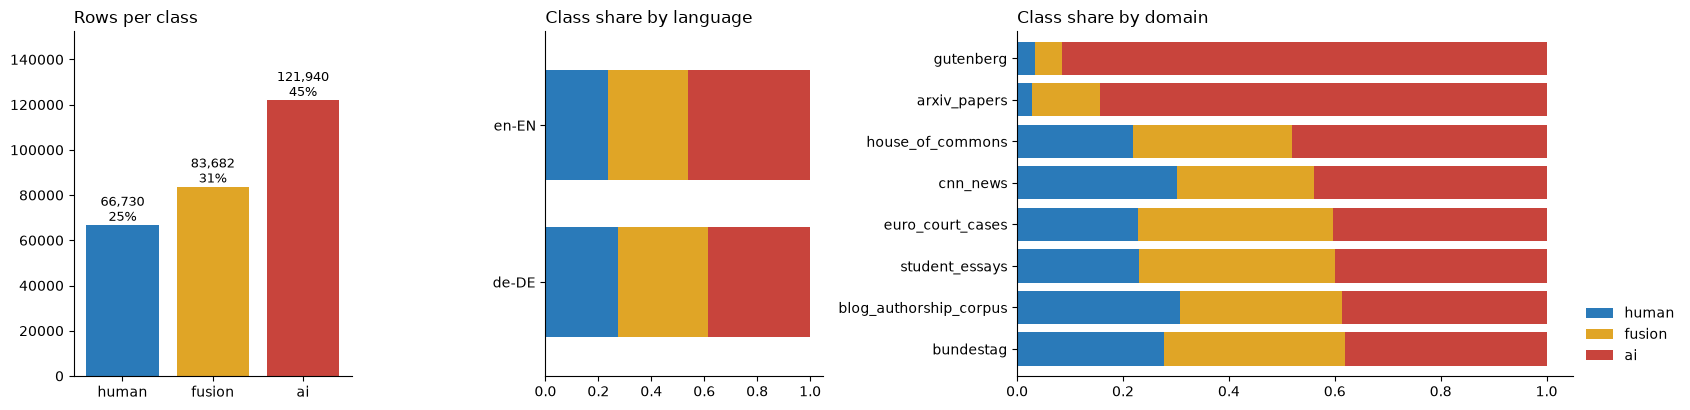

In [6]:
counts = train_df.label.value_counts().reindex(LABELS)
by_lang = pd.crosstab(train_df.lang, train_df.label, normalize='index')[LABELS]
by_domain = pd.crosstab(train_df.domain, train_df.label, normalize='index')[LABELS].sort_values('ai')
palette = [COLORS[c] for c in LABELS]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [1, 1, 2]})
axes[0].bar(counts.index, counts.values, color=palette)
for x, v in enumerate(counts.values):
    axes[0].text(x, v, f'{v:,}\n{v / counts.sum():.0%}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.25)
axes[0].set_title('Rows per class')
by_lang.plot.barh(stacked=True, ax=axes[1], color=palette, width=0.7, legend=False, title='Class share by language')
by_domain.plot.barh(stacked=True, ax=axes[2], color=palette, width=0.8, title='Class share by domain')
axes[2].legend(loc='lower left', bbox_to_anchor=(1, 0), frameon=False)
for ax in axes[1:]:
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Train vs test

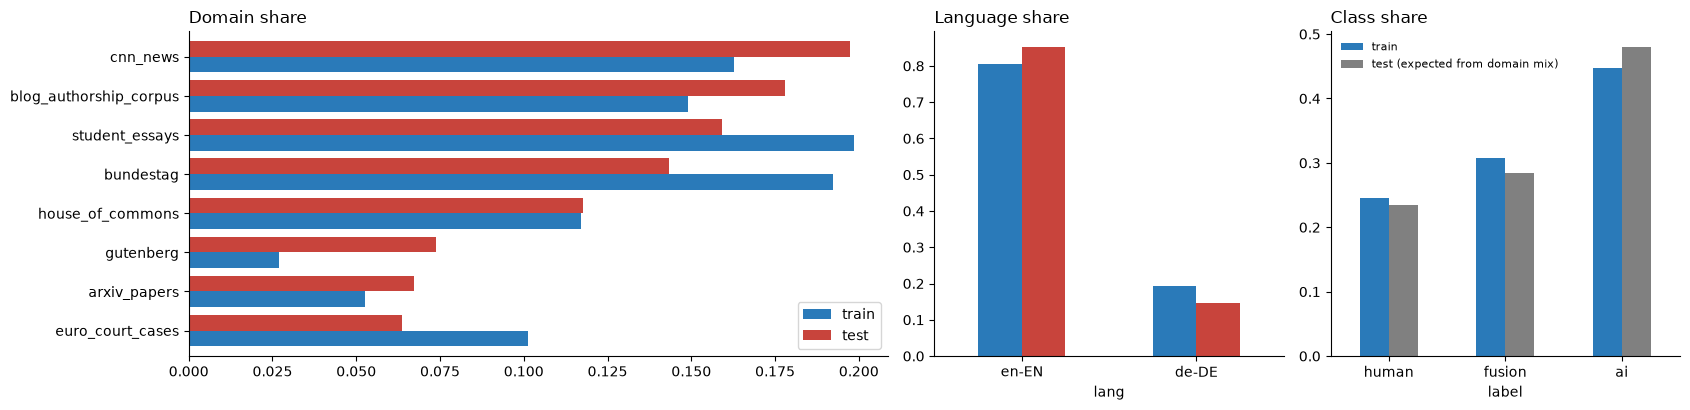

lang,de-DE,en-EN
domain,,
arxiv_papers,0,14290
blog_authorship_corpus,0,40547
bundestag,52343,0
cnn_news,0,44285
euro_court_cases,0,27578
gutenberg,428,6916
house_of_commons,0,31859
student_essays,0,54106


In [7]:
mix = pd.DataFrame({'train': train_df.domain.value_counts(normalize=True),
                    'test': test_df.domain.value_counts(normalize=True)}).sort_values('test')
langs = pd.DataFrame({'train': train_df.lang.value_counts(normalize=True),
                      'test': test_df.lang.value_counts(normalize=True)})
expected = pd.DataFrame({'train': counts / counts.sum(),
                         'test (expected from domain mix)': by_domain.mul(mix.test, axis=0).sum().reindex(LABELS)})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={'width_ratios': [2, 1, 1]})
mix.plot.barh(ax=axes[0], color=[COLORS['train'], COLORS['test']], width=0.8, title='Domain share')
langs.plot.bar(ax=axes[1], color=[COLORS['train'], COLORS['test']], rot=0, legend=False, title='Language share')
expected.plot.bar(ax=axes[2], color=[COLORS['train'], 'gray'], rot=0, title='Class share')
axes[0].set_ylabel('')
axes[2].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

display(pd.crosstab(train_df.domain, train_df.lang))

### Text length

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2), gridspec_kw={'width_ratios': [1.2, 1.6, 1]})
bins = np.geomspace(20, 3000, 40)
for label in LABELS:
    axes[0].hist(train_df.words[train_df.label == label], bins=bins, density=True, histtype='step', lw=2,
                 color=COLORS[label], label=label)
axes[0].hist(test_df.words, bins=bins, density=True, histtype='step', lw=2, ls='--', color='gray', label='test')
axes[0].set(xscale='log', xlabel='words', yticks=[], title='Text length by class')
legend_headroom(axes[0], ncol=2)

order = train_df.groupby('domain').words.median().sort_values().index
sns.boxplot(data=train_df, x='words', y='domain', hue='label', hue_order=LABELS, order=order, palette=COLORS,
            showfliers=False, log_scale=True, ax=axes[1])
axes[1].set(ylabel='', title='Text length by domain and class')
axes[1].get_legend().remove()  # same colours as the left plot

limits = np.arange(100, 3001, 50)
for label in LABELS:
    words = train_df.words[train_df.label == label].to_numpy()
    axes[2].plot(limits, [(words > n).mean() for n in limits], color=COLORS[label], lw=2, label=label)
axes[2].plot(limits, [(test_df.words > n).mean() for n in limits], color='gray', ls='--', lw=2, label='test')
axes[2].axvline(512, color='black', lw=1, ls=':')
axes[2].set(xscale='log', xlabel='words', ylabel='share of texts longer', title='Texts longer than N words')
legend_headroom(axes[2], ncol=2)
plt.tight_layout()
plt.show()

### Examples

In [9]:
def show_examples(domain, n_chars=600):
    rows = train_df[train_df.domain == domain].groupby('label').sample(1, random_state=SEED)
    for row in rows.set_index('label').reindex(LABELS).itertuples():
        print(f'--- {row.Index} ({row.lang}, {row.words} words)')
        print(textwrap.fill(row.text[:n_chars], 110), '...\n')


show_examples('cnn_news')
show_examples('bundestag')

--- human (en-EN, 439 words)
Luis Suarez looks set to be fit for Uruguay's clash with England in Sao Paulo on June 19 after saying his knee
is 'better'. The Liverpool striker needed surgery on his knee, leaving Uruguay sweating on the fitness of
their star striker. But, in a video message recorded for 888 poker, Suarez said he is on the road to recovery.
And the 27-year-old looked in fine form as he trained with the Uruguay squad just outside their base in Belo
Horizonte team on Tuesday. Road to recovery: Suarez said that his knee is getting 'better' ahead of the World
Cup . Fit and fresh: Suarez trained with the Uruguay ...

--- fusion (en-EN, 554 words)
A couple who were reported missing by police have been arrested for speeding through suburban streets and
crashing into motorists - with their newborn son on board. Ashley Groizard, 20, and Michael Holman, 32,
sparked a police search after disappearing with their son from the Hunter Valley in NSW, and were found by
authorities after b

### Fusion vs its human source

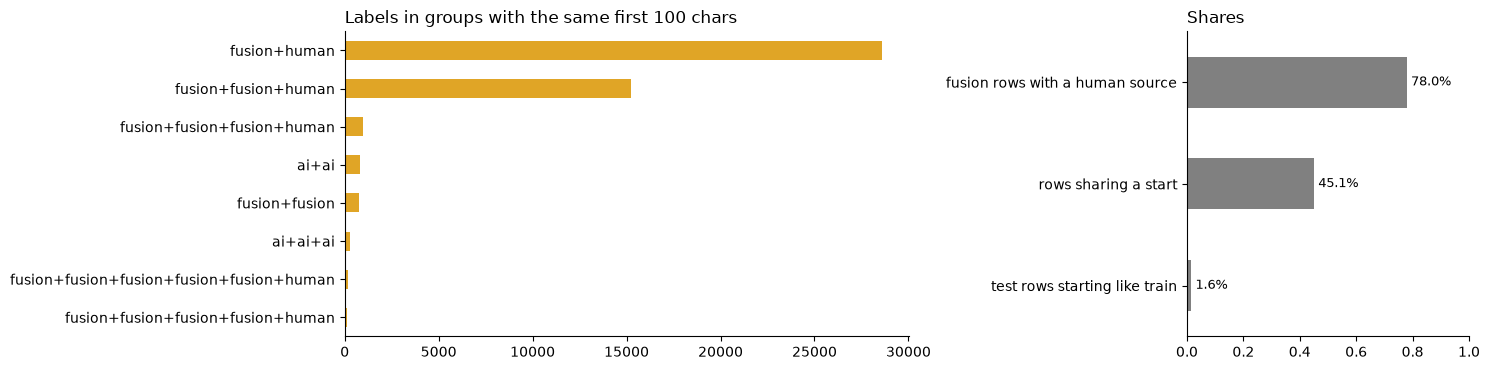

In [10]:
PREFIX_CHARS = 100
train_df['prefix'] = train_df.text.str[:PREFIX_CHARS]
shared = train_df[train_df.prefix.map(train_df.prefix.value_counts()) > 1]
combos = shared.groupby('prefix').label.agg(lambda s: '+'.join(sorted(s)))
fusion_with_source = train_df[train_df.label == 'fusion'].prefix.isin(
    set(train_df[train_df.label == 'human'].prefix)).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={'width_ratios': [2, 1]})
combos.value_counts().head(8).sort_values().plot.barh(ax=axes[0], color=COLORS['fusion'],
                                                      title='Labels in groups with the same first 100 chars')
axes[0].set_ylabel('')
shares = pd.Series({'rows sharing a start': len(shared) / len(train_df),
                    'fusion rows with a human source': fusion_with_source,
                    'test rows starting like train': test_df.text.str[:PREFIX_CHARS].isin(set(train_df.prefix)).mean()})
shares.sort_values().plot.barh(ax=axes[1], color='gray', xlim=(0, 1), title='Shares')
for y, v in enumerate(shares.sort_values()):
    axes[1].text(v, y, f' {v:.1%}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
def compare_pair(human, fusion):
    h, f = human.split(), fusion.split()
    blocks = [b for b in SequenceMatcher(None, h, f, autojunk=False).get_matching_blocks() if b.size]
    copied = np.zeros(len(f), bool)
    for b in blocks:
        copied[b.b:b.b + b.size] = True
    first_change = blocks[0].size if blocks and blocks[0].a == blocks[0].b == 0 else 0
    return {'copied': copied.mean(), 'first_change': first_change / len(f), 'length_ratio': len(f) / len(h),
            'copied_by_tenth': [chunk.mean() for chunk in np.array_split(copied, 10)]}


pair_keys = combos[combos == 'fusion+human']
pair_keys = pair_keys.sample(min(500, len(pair_keys)), random_state=SEED).index
pairs = shared[shared.prefix.isin(pair_keys)].pivot(index='prefix', columns='label', values='text')
pair_stats = pd.DataFrame([compare_pair(r.human, r.fusion) for r in pairs.itertuples()])
pair_stats['domain'] = shared.drop_duplicates('prefix').set_index('prefix').domain.reindex(pairs.index).values
by_tenth = np.vstack(pair_stats.copied_by_tenth).mean(axis=0)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].bar(np.arange(1, 11), by_tenth, color=COLORS['fusion'])
axes[0].set_xticks(np.arange(1, 11), [f'{10 * k}%' for k in range(1, 11)])
axes[0].set(ylim=(0, 1), xlabel='position in the fusion text', title='Words copied from the human source')
axes[1].hist(pair_stats.first_change, bins=20, color=COLORS['fusion'])
axes[1].set(xlabel='share of the text before the first change', ylabel='pairs', title='Where the rewrite starts')
pair_stats.groupby('domain')[['copied', 'first_change', 'length_ratio']].median().sort_values('copied').plot.barh(
    ax=axes[2], color=[COLORS['fusion'], COLORS['human'], 'gray'], title='Medians by domain')
axes[2].set_ylabel('')
legend_right(axes[2], fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
row = pairs.iloc[0]
h, f = row.human.split(), row.fusion.split()
for tag, a1, a2, b1, b2 in SequenceMatcher(None, h, f, autojunk=False).get_opcodes()[:8]:
    if tag == 'equal':
        print(f'= {a2 - a1} words the same')
    else:
        print(f'{tag}\n  human:  {" ".join(h[a1:a2])[:150]}\n  fusion: {" ".join(f[b1:b2])[:150]}')

= 557 words the same
replace
  human:  In conclusion, the
  fusion: The
= 2 words the same
replace
  human:  should stay where
  fusion: may seem like an outdated system, but its benefits far outweigh any perceived inconveniences. It acts as a safeguard against rash decisions made by vo
= 1 words the same
replace
  human:  is because it was created by the founding fathers, it keeps communism and socialism out, and it is in the constitution. If the United States were to r
  fusion: fosters a broader understanding
= 2 words the same
replace
  human:  country itself, for they were the ones who fought for the freedom of the country.
  fusion: nation's needs and prevents candidates from focusing solely on densely populated areas.


### Surface style

In [ ]:
def style_features(text):
    words = text.split()
    sentences = [s for s in re.split(r'(?<=[.!?])\s+', text) if s]
    return {
        'words per sentence': len(words) / max(len(sentences), 1),
        'type-token ratio (200 words)': len(set(w.lower() for w in words[:200])) / min(len(words), 200),
        'commas per 100 words': 100 * text.count(',') / len(words),
        'curly quotes': any(c in text for c in '“”‘’„'),
        'em dash': '—' in text,
        'space before , or .': bool(re.search(r'\s[,.]', text)),
    }


style_rows = train_df.sample(30_000, random_state=SEED)
style = pd.DataFrame([style_features(t) for t in style_rows.text], index=style_rows.index)
style[['label', 'lang']] = style_rows[['label', 'lang']]
numeric, flags = list(style.columns[:3]), list(style.columns[3:6])

fig, axes = plt.subplots(1, 6, figsize=(22, 3.8))
for ax, col in zip(axes[:3], numeric):
    sns.boxplot(data=style, x='label', y=col, order=LABELS, hue='label', palette=COLORS, showfliers=False,
                legend=False, ax=ax)
    ax.set(xlabel='', ylabel='', title=col)
for ax, col in zip(axes[3:], flags):
    share = style.groupby(['lang', 'label'])[col].mean().unstack()[LABELS]
    share.plot.bar(ax=ax, color=palette, rot=0, legend=False, title=f'{col}: share of texts')
    ax.set_xlabel('')
legend_headroom(axes[-1], *class_handles())
plt.tight_layout()
plt.show()

### Fusion boundary

In [ ]:
def shared_words(a, b):
    a, b = a.split(), b.split()
    return next((i for i, (x, y) in enumerate(zip(a, b)) if x != y), min(len(a), len(b)))


def boundary_char(text, n_words):
    starts = [m.start() for m in re.finditer(r'\S+', text)]
    return starts[n_words] if n_words < len(starts) else len(text)


# fusion = human source + AI continuation: the boundary is where the shared word prefix ends
human_source = train_df[train_df.label == 'human'].drop_duplicates('prefix').set_index('prefix').text
paired = train_df[(train_df.label == 'fusion') & train_df.prefix.isin(human_source.index)]
boundary = paired[['id', 'domain', 'lang', 'words']].copy()
boundary['same_words'] = [shared_words(t, human_source[p]) for t, p in zip(paired.text, paired.prefix)]
boundary['char'] = [boundary_char(t, n) for t, n in zip(paired.text, boundary.same_words)]
boundary['rel'] = boundary.same_words / boundary.words
boundary['ai_words'] = boundary.words - boundary.same_words
print(f'fusion rows with a human source in train: {len(paired):,} ({len(paired) / (train_df.label == "fusion").sum():.1%}); '
      f'median boundary at {boundary.rel.median():.0%} of the text, {boundary.same_words.median():.0f} words')

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for lang, color in zip(['en-EN', 'de-DE'], [COLORS['human'], COLORS['ai']]):
    axes[0].hist(boundary.rel[boundary.lang == lang], bins=40, range=(0, 1), density=True, histtype='step', lw=2,
                 color=color, label=lang)
axes[0].set(xlabel='boundary / text length (words)', yticks=[], title='Where the AI continuation starts')
legend_headroom(axes[0])
order = boundary.groupby('domain').rel.median().sort_values().index
sns.boxplot(data=boundary, x='rel', y='domain', order=order, color=COLORS['fusion'], showfliers=False, ax=axes[1])
axes[1].set(xlabel='boundary / text length', ylabel='', title='Boundary by domain')
for name, col, color in [('human part', 'same_words', COLORS['human']), ('AI part', 'ai_words', COLORS['ai'])]:
    axes[2].hist(boundary[col].clip(lower=1), bins=np.geomspace(1, 3000, 40), histtype='step', lw=2, color=color,
                 label=name)
axes[2].set(xscale='log', xlabel='words', yticks=[], title='Length of the human and AI parts')
legend_headroom(axes[2])
plt.tight_layout()
plt.show()

In [ ]:
# anatomy of 40 English fusion texts: the copied human start, the AI continuation, and the encoder window
ENC_WORDS = int((ENCODER_MAX_LEN - 2) / 2 / 1.45)  # about 1.45 XLM-R tokens per English word
show = boundary[boundary.lang == 'en-EN'].sample(40, random_state=SEED).sort_values('rel').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(15, 7))
ax.barh(show.index, show.same_words, color=COLORS['human'], height=0.75, edgecolor='white', linewidth=1,
        label='copied from the human source')
ax.barh(show.index, show.ai_words, left=show.same_words, color=COLORS['ai'], height=0.75, edgecolor='white',
        linewidth=1, label='AI continuation')
long_text = show.words > 2 * ENC_WORDS
ax.scatter(np.full(long_text.sum(), ENC_WORDS), show.index[long_text], marker='|', s=120, color='black',
           label='head window ends')
ax.scatter((show.words - ENC_WORDS)[long_text], show.index[long_text], marker='|', s=120, color='gray',
           label='tail window starts')
ax.set(xlabel='words', yticks=[], ylabel='fusion texts, sorted by where the AI part starts',
       title='Anatomy of fusion texts: the AI part often starts in the middle that head + tail truncation drops')
legend_right(ax)
plt.tight_layout()
plt.show()

### Discriminative words

In [ ]:
def log_odds_z(counts_a, counts_b, prior):
    # log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008), as a z-score
    n_a, n_b, a0 = counts_a.sum(), counts_b.sum(), prior.sum()
    delta = (np.log((counts_a + prior) / (n_a + a0 - counts_a - prior))
             - np.log((counts_b + prior) / (n_b + a0 - counts_b - prior)))
    return delta / np.sqrt(1 / (counts_a + prior) + 1 / (counts_b + prior))


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, lang in zip(axes, ['en-EN', 'de-DE']):
    rows = train_df[(train_df.lang == lang) & train_df.label.isin(['ai', 'human'])]
    rows = rows.groupby('label').sample(min(15_000, rows.label.value_counts().min()), random_state=SEED)
    vec = CountVectorizer(token_pattern=r'(?u)\b[^\W\d_]{2,}\b', min_df=20, dtype=np.float32)
    X = vec.fit_transform(rows.text)
    counts = {c: np.asarray(X[(rows.label == c).to_numpy()].sum(0)).ravel() for c in ['ai', 'human']}
    z = pd.Series(log_odds_z(counts['ai'], counts['human'], 0.1 * (counts['ai'] + counts['human'])),
                  index=vec.get_feature_names_out())
    top = pd.concat([z.nsmallest(15), z.nlargest(15)]).sort_values()
    ax.barh(top.index, top.values, color=np.where(top > 0, COLORS['ai'], COLORS['human']))
    ax.axvline(0, color='gray', lw=1)
    ax.set(xlabel='z (left: human, right: ai)', title=f'{lang}: words that separate ai from human')
plt.tight_layout()
plt.show()

### Rhythm and vocabulary

In [ ]:
FUNCTION_WORDS = {
    'en-EN': set('the a an and or but of to in on at for with by from as is are was were be been it this that these '
                 'those which who not'.split()),
    'de-DE': set('der die das den dem des ein eine und oder aber von zu im in an auf für mit bei aus als ist sind war '
                 'waren es diese dieser nicht wir sie ich'.split()),
}


def rhythm_features(text, lang):
    words = text.split()
    lower = [w.strip('.,;:!?"()„“”').lower() for w in words]
    sentences = np.array([len(s.split()) for s in re.split(r'(?<=[.!?])\s+', text) if s.strip()])
    windows = [lower[i:i + 50] for i in range(0, max(len(lower) - 49, 1), 25)]
    n = max(len(words), 1)
    return {'sentence length CV': sentences.std() / max(sentences.mean(), 1),
            'MATTR (50 words)': np.mean([len(set(w)) / max(len(w), 1) for w in windows]),
            'function-word share': sum(w in FUNCTION_WORDS[lang] for w in lower) / n,
            '; and : per 100 words': 100 * (text.count(';') + text.count(':')) / n,
            'brackets per 100 words': 100 * text.count('(') / n,
            '! and ? per 100 words': 100 * (text.count('!') + text.count('?')) / n}


rhythm = pd.DataFrame([rhythm_features(t, l) for t, l in zip(style_rows.text, style_rows.lang)], index=style_rows.index)
rhythm[['label', 'lang']] = style_rows[['label', 'lang']]
fig, axes = plt.subplots(2, 3, figsize=(18, 7.5))
for ax, col in zip(axes.ravel(), rhythm.columns[:6]):
    sns.boxplot(data=rhythm, x='lang', y=col, hue='label', hue_order=LABELS, palette=COLORS, showfliers=False, ax=ax,
                legend=False)
    ax.set(xlabel='', ylabel='', title=col)
legend_above(fig, *class_handles(), ncol=3)
plt.show()

### Style along the text

In [ ]:
def decile_style(text, lang):
    words = text.split()
    parts = [words[a:b] for a, b in zip(*(lambda e: (e[:-1], e[1:]))(np.linspace(0, len(words), 11).astype(int)))]
    return np.array([[np.mean([len(w.strip(STRIP_CHARS)) for w in p]) if p else np.nan,
                      100 * sum(w.endswith(',') for w in p) / max(len(p), 1),
                      100 * sum(w.strip(STRIP_CHARS).lower() in FUNCTION_WORDS[lang] for w in p) / max(len(p), 1)]
                     for p in parts])


STRIP_CHARS = '.,;:!?"()„“”'
drift_rows = style_rows[style_rows.words >= 150]
drift = np.stack([decile_style(t, l) for t, l in zip(drift_rows.text, drift_rows.lang)])
names = ['mean word length', 'commas per 100 words', 'function words per 100 words']
fig, axes = plt.subplots(2, 3, figsize=(18, 7), sharex=True)
for r, lang in enumerate(['en-EN', 'de-DE']):
    for j, name in enumerate(names):
        ax = axes[r, j]
        for label in LABELS:
            m = ((drift_rows.label == label) & (drift_rows.lang == lang)).to_numpy()
            ax.plot(np.arange(1, 11), np.nanmean(drift[m, :, j], 0), marker='o', lw=2, color=COLORS[label],
                    label=label)
        ax.set(title=f'{lang}: {name}', xticks=range(1, 11))
for ax in axes[1]:
    ax.set_xlabel('tenth of the text')
legend_above(fig, *axes[0, 0].get_legend_handles_labels(), ncol=3)
plt.show()

### Zipf and Heaps

In [ ]:
WORD = re.compile(r'[^\W\d_]+')
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for j, lang in enumerate(['en-EN', 'de-DE']):
    for label in LABELS:
        pool = train_df.text[(train_df.lang == lang) & (train_df.label == label)]
        texts = pool.sample(min(2_000, len(pool)), random_state=SEED)
        tokens = [w.lower() for t in texts for w in WORD.findall(t)]
        freq = np.sort(np.array(list(Counter(tokens).values())))[::-1] / len(tokens)
        axes[j].loglog(np.arange(1, len(freq) + 1), freq, lw=2, color=COLORS[label], label=label)
        seen, growth = set(), []
        for k, w in enumerate(tokens[:400_000]):
            seen.add(w)
            if k % 2_000 == 0:
                growth.append((k + 1, len(seen)))
        axes[2 + j].plot(*np.array(growth).T, lw=2, color=COLORS[label], label=label)
    axes[j].set(xlabel='word rank', ylabel='relative frequency', title=f'{lang}: Zipf (2,000 texts per class)')
    axes[2 + j].set(xlabel='tokens read', ylabel='distinct words', title=f'{lang}: Heaps (vocabulary growth)')
for j, ax in enumerate(axes):
    ax.legend(frameon=False, loc='upper right' if j < 2 else 'upper left')
plt.tight_layout()
plt.show()

### Map of texts (LSA)

In [ ]:
# 2-D LSA projection (TF-IDF + truncated SVD) fitted on a train sample only, one map per language
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, lang in zip(axes, ['en-EN', 'de-DE']):
    rows = train_df[train_df.lang == lang].sample(frac=1, random_state=SEED).groupby('label').head(1_500)
    X = TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), max_features=50_000, sublinear_tf=True,
                        dtype=np.float32).fit_transform(rows.text)
    xy = TruncatedSVD(2, random_state=SEED).fit_transform(X)
    for label in LABELS:
        m = (rows.label == label).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=5, alpha=0.35, color=COLORS[label], label=label)
    ax.set(xticks=[], yticks=[], title=f'{lang}: char 2-4-gram TF-IDF, first two LSA components')
legend_right(axes[1], markerscale=4)
plt.tight_layout()
plt.show()

### Train vs test shift

In [ ]:
def shift_features(texts):
    chars, words = texts.str.len(), texts.str.split().str.len()
    return pd.DataFrame({
        'log chars': np.log(chars), 'chars per word': chars / words,
        'zlib ratio': texts.map(lambda t: len(zlib.compress(t.encode(), 9)) / len(t.encode())),
        'commas / 100 words': 100 * texts.str.count(',') / words,
        'sentence ends / 100 words': 100 * texts.str.count(r'[.!?](?:\s|$)') / words,
        'digits / 100 chars': 100 * texts.str.count(r'\d') / chars,
        'curly quotes': texts.str.contains('[“”„’]').astype(float)})


# no model is fitted on test: each feature is compared with a two-sample KS test inside a domain
shift_train = train_df.sample(frac=1, random_state=SEED).groupby('domain').head(3_000)
f_train, f_test = shift_features(shift_train.text), shift_features(test_df.text)
ks = pd.DataFrame({col: {d: ks_2samp(f_train[col][shift_train.domain == d], f_test[col][test_df.domain == d]).statistic
                         for d in sorted(test_df.domain.unique())} for col in f_train.columns})

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(ks, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=0.3, cbar=False, ax=ax)
ax.set(title='KS distance between train and test inside each domain (0 = same distribution)')
plt.tight_layout()
plt.show()

### Length in encoder tokens

In [ ]:
enc_tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)
BODY = ENCODER_MAX_LEN - 2
token_rows = train_df.sample(frac=1, random_state=SEED).groupby(['domain', 'label']).head(300)
token_rows = token_rows.assign(tokens=[len(x) for x in enc_tokenizer(token_rows.text.tolist(),
                                                                     add_special_tokens=False).input_ids])

# where the fusion boundary lands in the head + tail window that the encoder sees
sample = boundary.sample(min(5_000, len(boundary)), random_state=SEED)
enc = enc_tokenizer(train_df.text.loc[sample.index].tolist(), add_special_tokens=False, return_offsets_mapping=True)
n_tok = np.array([len(x) for x in enc.input_ids])
at = np.array([np.searchsorted([s for s, _ in off], c) for off, c in zip(enc.offset_mapping, sample.char)])
place = pd.Series(np.select([n_tok <= BODY, at < BODY // 2, at >= n_tok - (BODY - BODY // 2)],
                            ['whole text fits', 'in the head', 'in the tail'], 'in the dropped middle'))

fig, axes = plt.subplots(1, 3, figsize=(18, 4), gridspec_kw={'width_ratios': [1.6, 1, 1]})
share = (token_rows.tokens > BODY).groupby([token_rows.domain, token_rows.label]).mean().unstack()[LABELS]
sns.heatmap(share, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=axes[0])
axes[0].set(xlabel='', ylabel='', title=f'Share of texts longer than {BODY} {ENCODER_NAME} tokens')
for lang, color in zip(['en-EN', 'de-DE'], [COLORS['human'], COLORS['ai']]):
    rows = token_rows[token_rows.lang == lang]
    axes[1].hist(rows.tokens / rows.words, bins=40, histtype='step', lw=2, density=True, color=color, label=lang)
axes[1].set(xlabel='tokens per word', yticks=[], title='Tokenizer cost by language')
legend_headroom(axes[1])
place.value_counts(normalize=True).sort_values().plot.barh(ax=axes[2], color=COLORS['fusion'], xlim=(0, 1),
                                                          title='Fusion boundary in the head + tail window')
plt.tight_layout()
plt.show()

## Validation split

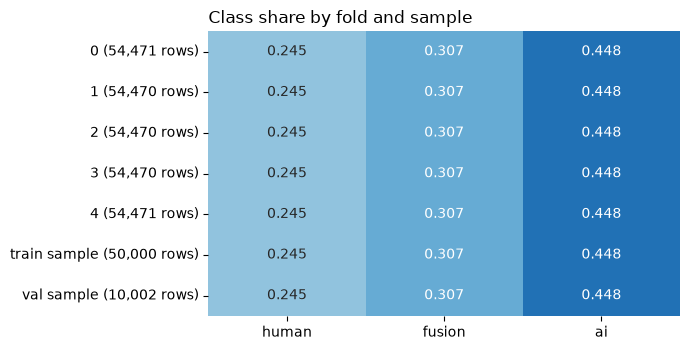

In [14]:
def stratified_sample(df, n):
    return df.groupby(['label', 'domain']).sample(frac=min(n / len(df), 1), random_state=SEED)


sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_df['fold'] = -1
for k, (_, rows) in enumerate(sgkf.split(train_df, train_df.label + '|' + train_df.domain, groups=train_df.prefix)):
    train_df.loc[train_df.index[rows], 'fold'] = k
assert (train_df.fold >= 0).all() and train_df.groupby('prefix').fold.nunique().max() == 1

is_val = train_df.fold == VAL_FOLD
train_part = stratified_sample(train_df[~is_val], TRAIN_SAMPLE)
val_part = stratified_sample(train_df[is_val], VAL_SAMPLE)
assert not set(train_part.prefix) & set(val_part.prefix)

splits = train_df[['id', 'fold']].assign(split=np.where(is_val, 'val', 'train')).set_index('id')
splits['in_sample'] = splits.index.isin(train_part.id) | splits.index.isin(val_part.id)
splits.to_csv(Path(RUNS) / 'splits.csv')

fold_share = pd.crosstab(train_df.fold, train_df.label, normalize='index')[LABELS]
fold_share.loc['train sample'] = train_part.label.value_counts(normalize=True)
fold_share.loc['val sample'] = val_part.label.value_counts(normalize=True)
fold_rows = train_df.fold.value_counts().sort_index().tolist() + [len(train_part), len(val_part)]

fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(fold_share, annot=True, fmt='.3f', cmap='Blues', vmin=0, vmax=0.6, cbar=False, ax=ax)
ax.set_yticklabels([f'{i} ({n:,} rows)' for i, n in zip(fold_share.index, fold_rows)], rotation=0)
ax.set(xlabel='', ylabel='', title='Class share by fold and sample')
plt.tight_layout()
plt.show()

### Groups and folds

In [ ]:
# every prefix group (a human text and its fusion rewrites) stays in one fold; a random split would leak twins
group_type = train_df.prefix.map(combos.str.split('+').map(lambda l: '+'.join(sorted(set(l))))).fillna(train_df.label)
random_fold = np.empty(len(train_df), int)
for k, (_, rows) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train_df)):
    random_fold[rows] = k


def twin_in_other_fold(folds):
    folds_per_prefix = pd.Series(folds, index=train_df.index).groupby(train_df.prefix).nunique()
    return (train_df.prefix.map(folds_per_prefix) > 1).mean()


leak = pd.Series({'random KFold': twin_in_other_fold(random_fold),
                  'StratifiedGroupKFold by prefix': twin_in_other_fold(train_df.fold.to_numpy())})
twins = pd.Series({'train': train_df.prefix.duplicated(keep=False).mean(),
                   'val sample': val_part.prefix.map(train_df.prefix.value_counts()).gt(1).mean(),
                   'test': test_df.text.str[:PREFIX_CHARS].duplicated(keep=False).mean()})
mix = pd.crosstab(train_df.fold, group_type, normalize='index')
mix = mix[group_type.value_counts().index[:6]]

fig, axes = plt.subplots(1, 3, figsize=(19, 4), gridspec_kw={'width_ratios': [1, 1.6, 1]})
axes[0].barh(leak.index, leak.values, color=[COLORS['down'], COLORS['up']], height=0.6)
for y, v in enumerate(leak.values):
    axes[0].text(v, y, f' {v:.1%}', va='center')
axes[0].set(xlim=(0, max(leak.max() * 1.3, 0.05)), title='Rows whose prefix twin sits in another fold')
sns.heatmap(mix, annot=True, fmt='.3f', cmap='Blues', cbar=False, ax=axes[1])
axes[1].set(xlabel='', ylabel='fold', title='Group types in each fold (share of rows)')
axes[2].barh(twins.index, twins.values, color='gray', height=0.6)
for y, v in enumerate(twins.values):
    axes[2].text(v, y, f' {v:.1%}', va='center')
axes[2].set(xlim=(0, 0.6), title='Rows with a 100-char prefix twin')
plt.tight_layout()
plt.show()

## Experiment helpers

In [ ]:
TAG = 'full' if FULL_TRAIN else 'sample'
SHARDS, CKPTS, MODELS = (Path(RUNS) / d for d in ('shards', 'ckpt', 'models'))
for folder in (SHARDS, CKPTS, MODELS):
    folder.mkdir(parents=True, exist_ok=True)

def git_commit():
    try:
        return subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
    except OSError:
        return None


def atomic_write(file, write):
    # write to a temporary file, then rename: a killed process never leaves a half-written result behind
    file = Path(file)
    tmp = file.with_name(file.name + '.tmp')
    write(tmp)
    os.replace(tmp, file)


def atomic_csv(frame, file):
    atomic_write(file, frame.to_csv)


def atomic_json(obj, file):
    atomic_write(file, lambda f: f.write_text(json.dumps(obj, indent=1, default=str)))


def read_frame(file):
    return pd.read_csv(file, index_col=0, converters={0: str})


def params_key(params):
    return hashlib.md5(json.dumps(params, sort_keys=True, default=str).encode()).hexdigest()[:10]


def meta_file(file):
    return file.with_name(file.name + '.json')


def log_event(step, start, **extra):
    event = {'step': step, 'minutes': round((time.time() - start) / 60, 2),
             'peak_ram_gb': round(peak_ram_gb(), 1), 'peak_vram_gb': round(vram_gb(), 1), 'git': GIT,
             'time': time.strftime('%Y-%m-%d %H:%M:%S'), **extra}
    with open(Path(RUNS) / 'events.jsonl', 'a') as f:
        f.write(json.dumps(event, default=str) + '\n')
    log.info(f"{step}: done in {event['minutes']:.1f} min")


def is_fresh(file, key):
    if FORCE or not file.exists():
        return False
    if not meta_file(file).exists():  # cached before parameter keys existed: adopt it
        atomic_json({'key': key, 'adopted': True}, meta_file(file))
        log.info(f'{file.name}: adopted an existing cache')
        return True
    old = json.loads(meta_file(file).read_text()).get('key')
    if old != key:
        log.warning(f'{file.name}: parameters changed ({old} -> {key}), recomputing')
    return old == key


def cached(name, compute, **params):
    file, key = Path(RUNS) / name, params_key(params)
    if not is_fresh(file, key):
        log.info(f'{name}: computing')
        start = time.time()
        frame = compute()
        atomic_csv(frame, file)
        atomic_json({'key': key, 'params': params, 'rows': len(frame), 'git': GIT,
                     'minutes': round((time.time() - start) / 60, 2)}, meta_file(file))
        log_event(name, start, rows=len(frame), key=key)
    return read_frame(file)


def cached_object(name, build, **params):
    file, key = MODELS / f'{name}.pkl', params_key(params)
    if is_fresh(file, key):
        return joblib.load(file)
    start = time.time()
    obj = build()
    atomic_write(file, lambda f: joblib.dump(obj, f))
    atomic_json({'key': key, 'params': params, 'git': GIT}, meta_file(file))
    log_event(name, start, key=key)
    return obj


def run_shard(fn, args, file, k):
    atomic_csv(fn(*args), file)
    return k


def sharded(name, fn, make_args, n_shards, n_jobs=N_JOBS, **params):
    # shard k = fn(*make_args(k)) in its own file: after a crash only the missing shards run again
    folder = SHARDS / f'{name}-{params_key(params)}'

    def compute():
        folder.mkdir(parents=True, exist_ok=True)
        files = [folder / f'{k:04d}.csv' for k in range(n_shards)]
        todo = [k for k in range(n_shards) if not files[k].exists()]
        log.info(f'{name}: {n_shards - len(todo)}/{n_shards} shards ready, running {len(todo)}')
        jobs = (delayed(run_shard)(fn, make_args(k), files[k], k) for k in todo)
        for k in Parallel(n_jobs=n_jobs, return_as='generator_unordered')(jobs):
            log.info(f'{name}: shard {k + 1}/{n_shards} saved')
        return pd.concat([read_frame(f) for f in files])

    frame = cached(name, compute, shards=n_shards, **params)
    shutil.rmtree(folder, ignore_errors=True)
    return frame


def free_gpu():
    gc.collect()
    torch.cuda.empty_cache()


def run_status():
    rows = [{'artefact': f.name, 'state': 'ready', 'MB': f.stat().st_size / 2 ** 20,
             'saved': time.strftime('%m-%d %H:%M', time.localtime(f.stat().st_mtime))}
            for f in sorted([*Path(RUNS).glob('*.csv'), *MODELS.glob('*.p*')])]
    rows += [{'artefact': d.name, 'state': f'partial: {len(list(d.glob("*.csv")))} shards'} for d in SHARDS.iterdir()]
    for meta in CKPTS.glob('*/last.pt.json'):
        state = json.loads(meta.read_text())
        rows.append({'artefact': meta.parent.name, 'state': f"checkpoint: batch {state['done']:,}/{state['of']:,}"})
    return pd.DataFrame(rows).round(1) if rows else 'nothing cached yet'


GIT = git_commit()
CONFIG = {k: v for k, v in globals().items()
          if k.isupper() and isinstance(v, (bool, int, float, str, list, tuple, dict))}
atomic_json({'started': time.strftime('%Y-%m-%d %H:%M:%S'), 'git': GIT, 'python': platform.python_version(),
             'versions': {m.__name__: m.__version__ for m in (np, pd, sklearn, lgb, torch, transformers)},
             'gpu': torch.cuda.get_device_name(), 'config': CONFIG}, Path(RUNS) / 'manifest.json')
log.info(f'run started at git {GIT}, TAG={TAG}, RUNS={RUNS}')
display(run_status())


def class_f1(y_true, y_pred, label):
    return f1_score(y_true, y_pred, labels=[label], average='macro')


SCORING = {'macro_f1': 'f1_macro', **{f'f1_{c}': make_scorer(class_f1, label=c) for c in LABELS}}


def plot_by_class(frame, columns, title):
    fig, axes = plt.subplots(1, len(columns), figsize=(5 * len(columns), 3.6))
    for ax, col in zip(np.atleast_1d(axes), columns):
        sns.boxplot(x=frame.label, y=frame[col], order=LABELS, hue=frame.label, palette=COLORS, showfliers=False,
                    legend=False, ax=ax)
        ax.set(xlabel='', ylabel='', title=col)
    fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()

## A. Text artefacts

In [16]:
MONTHS = 'January|February|March|April|May|June|July|August|September|October|November|December'
BRITISH = 'colour|favour|labour|honour|behaviour|neighbour|centre|organisation|recognise|realise|programme|defence|analyse'
AMERICAN = 'color|favor|labor|honor|behavior|neighbor|center|organization|recognize|realize|program|defense|analyze'

ARTIFACTS = {
    'symbols': {
        'apostrophe_straight': r"\w'\w",
        'apostrophe_curly': r'\w[’ʼ]\w',
        'apostrophe_other': r'\w[`´′]\w',
        'dquote_straight': r'"',
        'dquote_curly': r'[“”]',
        'dquote_low_de': r'„',
        'guillemets': r'[«»‹›]',
        'squote_low_de': r'‚',
        'squote_curly_open': r'‘',
        'hyphen_variants': r'[‐‑‒―]',
        'en_dash': r'–',
        'em_dash': r'—',
        'minus_sign': r'−',
        'double_hyphen': r'(?<!-)--(?!-)',
        'soft_hyphen': r'­',
        'ellipsis_char': r'…',
        'three_dots': r'(?<!\.)\.\.\.(?!\.)',
        'spaced_dots': r'\. \. \.',
        'starts_with_dots': r'^\s*(?:\.\.\.|…)',
        'nbsp_thin_space': r'[   ]',
        'zero_width_bom': r'[​‌‍﻿]',
        'ligature': r'[ﬀ-ﬆ]',
        'nfd_combining': r'[̀-ͯ]',
        'mixed_script_word': r'\b(?=\w*[A-Za-z])(?=\w*[Ͱ-ϿЀ-ӿ])\w+',
        'mojibake': r'â€|Ã[\u0080-¿]|Â[ -¿]',
        'bullet': r'[•·]',
        'special_symbol': r'[×°€£‰©™½]',
        'emoji': r'[\U0001F300-\U0001FAFF☀-➿]',
    },
    'spacing': {
        'space_before_punct': r'\w [,.;:!?](?=\s|$)',
        'space_inside_quotes': r'(?:^|\s)" \w',
        'ptb_contraction': r"\w (?:n't|'s|'re|'ll|'ve|'m|'d)\b",
        'double_punct': r'[!?]{2,}|,,',
        'no_space_after_period': r'[a-z]\.[A-Z][a-z]',
    },
    'source': {
        'empty_slot': r'\b(?:the|of|in|from|at|on|aged|v\.|NO\.|von|der)\s+[,.](?=\s)',
        'llm_placeholder': r'\[(?:Image|Photo|Name|Your Name|Insert|Date|Location|Company)[^\]]{0,60}\]|\bXYZ\b',
        'url': r'https?://|www\.',
        'mention_hashtag': r'(?:^|\s)[@#]\w',
        'email': r'\b[\w.+-]+@[\w-]+\.\w+',
        'html_entity': r'&(?:amp|quot|lt|gt|nbsp|#\d+);|<br\s*/?>',
        'markdown': r'\*\*|(?:^|\s)#{1,6} \w',
        'latex': r'\$[^$]{1,80}\$|\\(?:cite|ref|begin|frac|emph)\b',
        'timestamp_meta': r'\[\d{1,2}/\d{1,2}/\d{4} \d',
        'stage_direction': r'\((?:Beifall|Zuruf|Zurufe|Heiterkeit|Lachen|Widerspruch)[^)]{0,80}\)'
                           r'|\[(?:Interruption|Laughter)[^\]]{0,40}\]|Hon\. Members',
    },
    'numbers': {
        'number_en_format': r'\b\d{1,3}(?:,\d{3})+(?:\.\d+)?\b',
        'number_de_format': r'\b\d{1,3}(?:\.\d{3})+(?:,\d+)?\b',
        'date_words': rf'\b(?:{MONTHS}) \d{{1,2}}\b',
        'date_numeric': r'\b\d{1,2}[./]\d{1,2}[./]\d{2,4}\b',
        'currency_symbol': r'[$£€]\s?\d',
        'percent_word': r'\b(?:per cent|percent|Prozent)\b',
        'percent_sign': r'%',
        'n_year_old_digits': r'\b\d+-year-old\b',
    },
    'words': {
        'all_caps_word': r'\b[A-ZÄÖÜ]{4,}\b',
        'contraction': r"\b\w+(?:n't|'s|'re|'ll|'ve|'m|'d)\b",
        'de_abbreviation': r'\b(?:z\. ?B\.|d\. ?h\.|bzw\.|usw\.|ggf\.|u\. ?a\.)',
        'british_spelling': rf'\b(?:{BRITISH})\w*',
        'american_spelling': rf'\b(?:{AMERICAN})(?:s|ed|ing|ation)?\b',
    },
}
PATTERNS = {name: re.compile(p, re.M) for group in ARTIFACTS.values() for name, p in group.items()}
ARTIFACT_GROUP = {name: group for group, items in ARTIFACTS.items() for name in items}


def count_artifacts(texts):
    return pd.DataFrame({name: [len(p.findall(t)) for t in texts] for name, p in PATTERNS.items()}, index=texts.index)

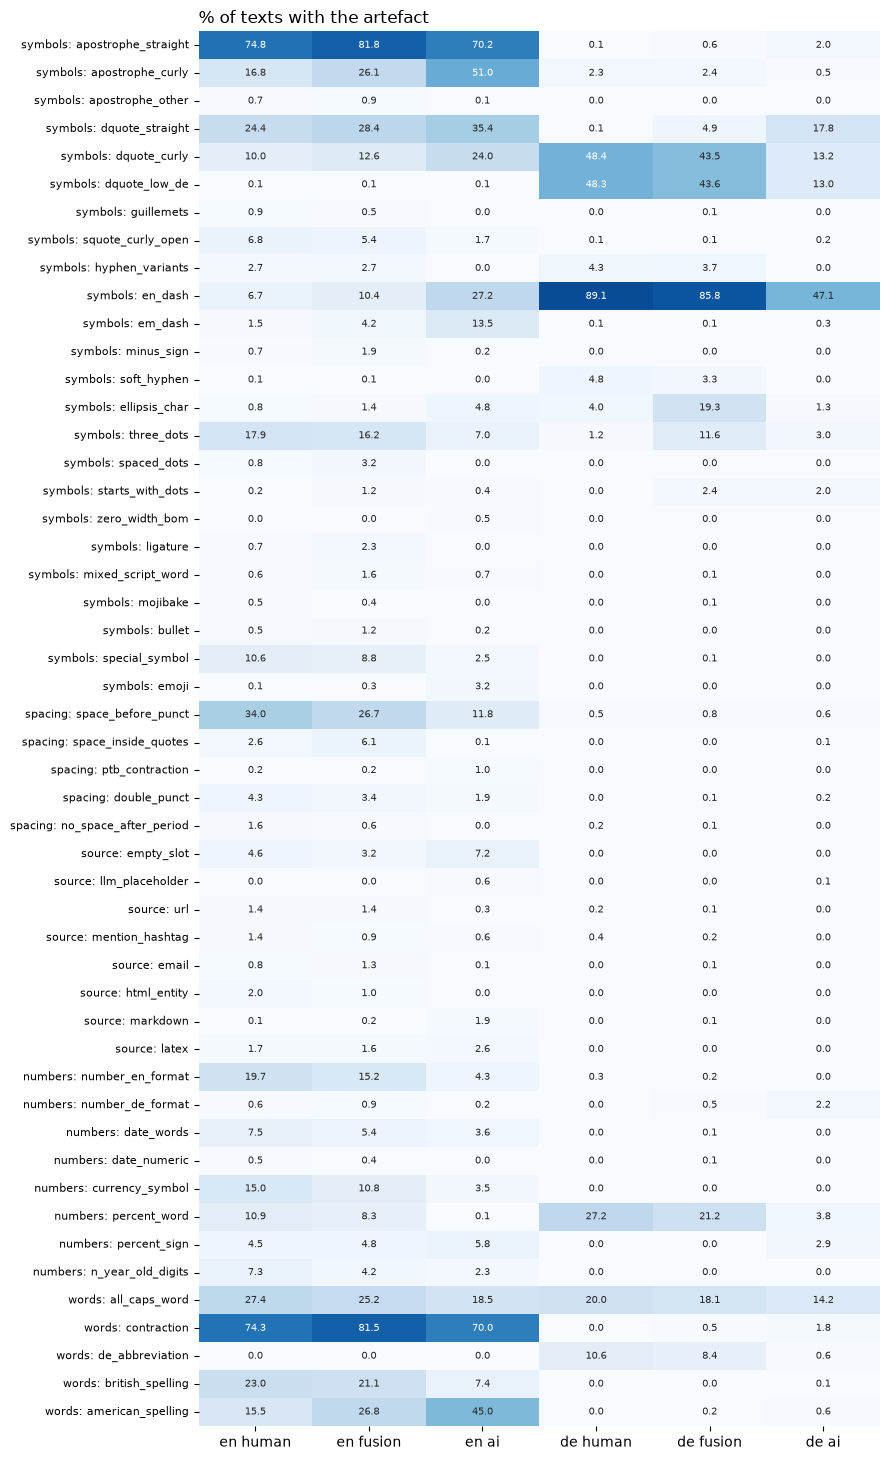

In [17]:
audit_rows = train_df[~is_val].sample(min(30_000, (~is_val).sum()), random_state=SEED)
audit = count_artifacts(audit_rows.text).gt(0).groupby([audit_rows.lang, audit_rows.label]).mean().T
audit = audit[[(lang, c) for lang in ['en-EN', 'de-DE'] for c in LABELS]]
shown = audit[(audit > 0.005).any(axis=1)]

fig, ax = plt.subplots(figsize=(9, 0.27 * len(shown) + 1.2))
sns.heatmap(shown * 100, annot=True, fmt='.1f', annot_kws={'fontsize': 7}, cmap='Blues', vmin=0, vmax=100,
            cbar=False, ax=ax)
ax.set_xticklabels([f'{lang[:2]} {c}' for lang, c in shown.columns])
ax.set_yticklabels([f'{ARTIFACT_GROUP[n]}: {n}' for n in shown.index], fontsize=8)
ax.set(xlabel='', ylabel='', title='% of texts with the artefact')
plt.tight_layout()
plt.show()

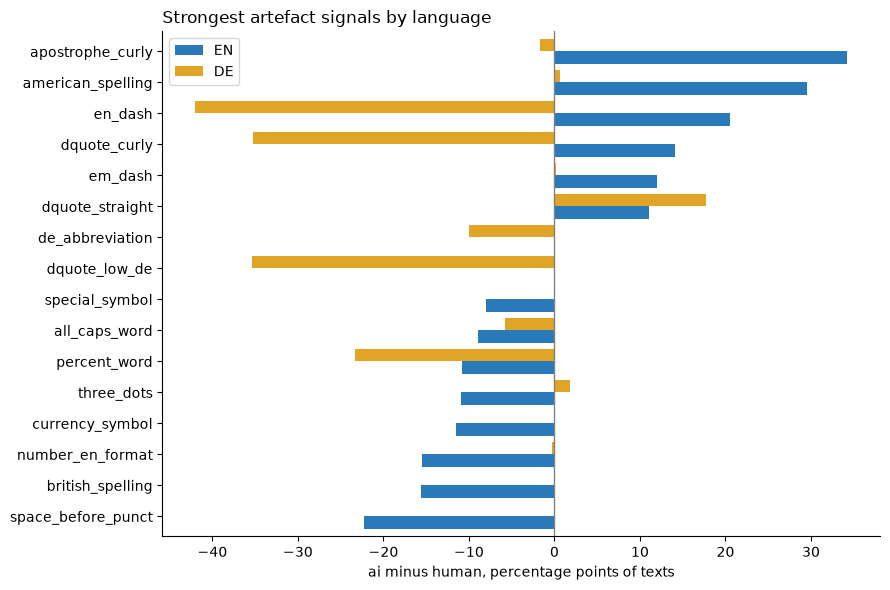

In [18]:
contrast = pd.DataFrame({lang[-2:]: audit[(lang, 'ai')] - audit[(lang, 'human')] for lang in ['en-EN', 'de-DE']}) * 100
top = contrast.loc[contrast.abs().max(axis=1).nlargest(16).index].sort_values('EN')

fig, ax = plt.subplots(figsize=(9, 6))
top.plot.barh(ax=ax, color=[COLORS['train'], COLORS['fusion']], width=0.8)
ax.axvline(0, color='gray', lw=1)
ax.set(xlabel='ai minus human, percentage points of texts', ylabel='', title='Strongest artefact signals by language')
plt.tight_layout()
plt.show()

## B. Normalisation search

In [19]:
QUOTES = str.maketrans({'“': '"', '”': '"', '„': '"', '«': '"', '»': '"',
                        '‹': "'", '›': "'", '‚': "'", '‘': "'", '’': "'",
                        'ʼ': "'", '`': "'", '´': "'", '′': "'"})
DASHES = str.maketrans({c: '-' for c in '‐‑‒–—―−'})
INVISIBLE = str.maketrans({'­': '', '​': '', '‌': '', '‍': '', '﻿': '',
                           ' ': ' ', ' ': ' ', ' ': ' '})
LIGATURES = re.compile(r'[ﬀ-ﬆ]')
SPACING = [
    (re.compile(r"(\w) (n't|'s|'re|'ll|'ve|'m|'d)\b"), r'\1\2'),
    (re.compile(r'(\w) ([,.;:!?])(?=\s|$)'), r'\1\2'),
    (re.compile(r'(^|\s)" (\w)'), r'\1"\2'),
    (re.compile(r'(\w) "(?=\s|$)'), r'\1"'),
    (re.compile(r'([a-z])\.([A-Z][a-z])'), r'\1. \2'),
]
WEB = [
    (re.compile(r'https?://\S+|www\.\S+'), ' URL '),
    (re.compile(r'\b[\w.+-]+@[\w-]+\.\w+'), ' EMAIL '),
    (re.compile(r'(^|\s)@+\w+'), r'\1@USER'),
]
NORM_FLAGS = ['unicode', 'web', 'quotes', 'dashes', 'ellipsis', 'spacing', 'digits', 'lowercase']


class TextNormalizer(BaseEstimator, TransformerMixin):
    def __init__(self, unicode=False, web=False, quotes=False, dashes=False, ellipsis=False, spacing=False,
                 digits=False, lowercase=False):
        self.unicode = unicode
        self.web = web
        self.quotes = quotes
        self.dashes = dashes
        self.ellipsis = ellipsis
        self.spacing = spacing
        self.digits = digits
        self.lowercase = lowercase

    def fit(self, X, y=None):
        return self

    def normalize(self, text):
        if self.unicode:
            text = unicodedata.normalize('NFC', text.translate(INVISIBLE))
            text = LIGATURES.sub(lambda m: unicodedata.normalize('NFKC', m.group()), text)
        if self.web:
            text = html.unescape(text)
            for pattern, repl in WEB:
                text = pattern.sub(repl, text)
        if self.quotes:
            text = text.translate(QUOTES)
        if self.dashes:
            text = text.translate(DASHES).replace('--', '-')
        if self.ellipsis:
            text = re.sub(r'…|\. \. \.', '...', text)
        if self.spacing:
            for pattern, repl in SPACING:
                text = pattern.sub(repl, text)
        if self.digits:
            text = re.sub(r'\d', '0', text)
        if self.lowercase:
            text = text.lower()
        return text

    def transform(self, X):
        return X.assign(clean=[self.normalize(t) for t in X.text])


class Stemmer(BaseEstimator, TransformerMixin):
    def __init__(self, enabled=False):
        self.enabled = enabled

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if not self.enabled:
            return X['clean'].tolist()
        from nltk.stem.snowball import SnowballStemmer
        stemmers = {'en-EN': SnowballStemmer('english'), 'de-DE': SnowballStemmer('german')}
        seen = {lang: {} for lang in stemmers}
        out = []
        for text, lang in zip(X['clean'], X['lang']):
            stem, cache = stemmers[lang].stem, seen[lang]
            out.append(' '.join(cache[w] if w in cache else cache.setdefault(w, stem(w))
                                for w in re.findall(r'\w+', text)))
        return out


class ArtifactCounts(BaseEstimator, TransformerMixin):
    def __init__(self, groups=tuple(ARTIFACTS)):
        self.groups = groups

    def fit(self, X, y=None):
        self.names_ = [n for n in PATTERNS if ARTIFACT_GROUP[n] in self.groups]
        return self

    def transform(self, X):
        counts = np.array([[len(PATTERNS[n].findall(t)) for n in self.names_] for t in X.text], dtype=np.float32)
        chars = X.text.str.len().to_numpy(np.float32)[:, None]
        words = X.text.str.split().str.len().to_numpy(np.float32)[:, None]
        feats = np.hstack([np.log1p(1000 * counts / chars), np.log(chars), np.log(words)])
        is_de = (X.lang == 'de-DE').to_numpy(np.float32)[:, None]
        return sparse.csr_matrix(np.hstack([feats * (1 - is_de), feats * is_de]))


def make_text_model(model=None):
    tfidf = dict(sublinear_tf=True, lowercase=False, dtype=np.float32, min_df=3, max_features=300_000)
    return Pipeline([
        ('norm', TextNormalizer()),
        ('features', ColumnTransformer([
            ('char', TfidfVectorizer(analyzer='char', ngram_range=(1, 4), **tfidf), 'clean'),
            ('word', Pipeline([('stemmer', Stemmer()), ('tfidf', TfidfVectorizer(ngram_range=(1, 2), **tfidf))]),
             ['clean', 'lang']),
            ('art', Pipeline([('counts', ArtifactCounts()), ('scale', MaxAbsScaler())]), ['text', 'lang']),
        ])),
        ('model', model if model is not None else LinearSVC(C=0.5)),
    ])


print(TextNormalizer(unicode=True, quotes=True, dashes=True, spacing=True, web=True).normalize(
    'He said : do n\'t go “now” — see www.x.com &amp; the ﬁle.Then'))

He said: don't go "now" - see  URL  & the file. Then


In [20]:
search_rows = stratified_sample(train_df[~is_val], SEARCH_SAMPLE).sample(frac=1, random_state=SEED)
X_search, y_search = search_rows[['text', 'lang']], search_rows.label
search_cv = list(StratifiedGroupKFold(SEARCH_FOLDS, shuffle=True, random_state=SEED).split(
    X_search, y_search + '|' + search_rows.domain, groups=search_rows.prefix))


def run_search(name, make_search, labels=None):
    def compute():
        search = make_search().fit(X_search, y_search)
        res = pd.DataFrame(search.cv_results_)
        out = res[[c for c in res if c.startswith(('mean_test', 'std_test', 'split')) or c == 'mean_fit_time']].copy()
        out['params'] = [repr(p) for p in res.params]
        out.index = labels if labels is not None else [f'candidate {i}' for i in range(len(out))]
        return out
    return cached(f'{name}.csv', compute)


def grid_of(configs):
    return GridSearchCV(make_text_model(), [{k: [v] for k, v in p.items()} for p in configs.values()],
                        cv=search_cv, scoring=SCORING, refit=False, n_jobs=N_JOBS, error_score='raise')


def compare(results, reference):
    folds = [c for c in results if c.startswith('split') and c.endswith('_test_macro_f1')]
    diff = results[folds].sub(results.loc[reference, folds], axis=1)
    table = pd.DataFrame({'macro_f1': results.mean_test_macro_f1, 'delta': diff.mean(axis=1),
                          'delta_std': diff.std(axis=1),
                          'all_folds_agree': (np.sign(diff).nunique(axis=1) == 1) & diff.ne(0).all(axis=1)})
    for c in LABELS:
        table[f'delta_{c}'] = results[f'mean_test_f1_{c}'] - results.loc[reference, f'mean_test_f1_{c}']
    return table


def plot_search(table, title):
    rows = table.sort_values('delta')
    fig, axes = plt.subplots(1, 2, figsize=(16, 0.38 * len(rows) + 1.5), gridspec_kw={'width_ratios': [2, 1]})
    colors = np.where(rows.delta > 0, COLORS['up'], COLORS['down'])
    alphas = np.where(rows.all_folds_agree, 1.0, 0.35)
    for y, (d, s, c, a) in enumerate(zip(rows.delta, rows.delta_std, colors, alphas)):
        axes[0].barh(y, d, xerr=s, color=c, alpha=a)
    axes[0].set_yticks(range(len(rows)), rows.index)
    axes[0].axvline(0, color='gray', lw=1)
    axes[0].set(xlabel='macro-F1 vs reference (pale = folds disagree)', title=title)
    sns.heatmap(rows[[f'delta_{c}' for c in LABELS]].iloc[::-1], annot=True, fmt='+.3f', cmap='RdBu', center=0,
                cbar=False, yticklabels=False, xticklabels=LABELS, ax=axes[1])
    axes[1].set_title('F1 vs reference by class')
    plt.tight_layout()
    plt.show()

### B1. Normalisation and artefact blocks

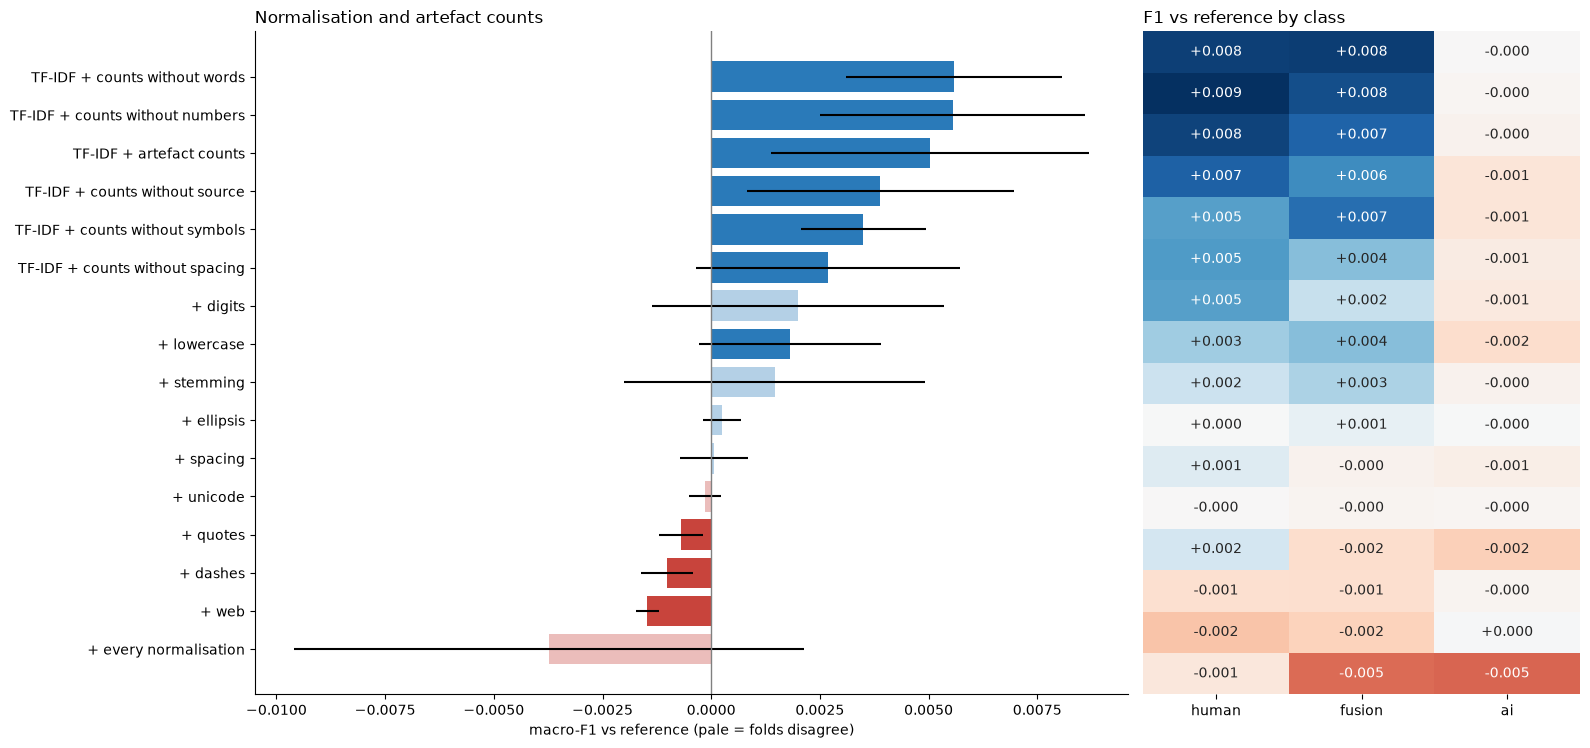

reference macro-F1 0.8268, artefact counts only 0.5802


In [21]:
TFIDF_ONLY = {'features__art': 'drop'}
REF_NORM = 'raw text, TF-IDF only'
norm_configs = {REF_NORM: TFIDF_ONLY}
norm_configs |= {f'+ {flag}': {**TFIDF_ONLY, f'norm__{flag}': True} for flag in NORM_FLAGS}
norm_configs['+ stemming'] = {**TFIDF_ONLY, 'features__word__stemmer__enabled': True}
norm_configs['+ every normalisation'] = {**TFIDF_ONLY, **{f'norm__{f}': True for f in NORM_FLAGS},
                                          'features__word__stemmer__enabled': True}
norm_configs['TF-IDF + artefact counts'] = {}
norm_configs |= {f'TF-IDF + counts without {g}': {'features__art__counts__groups': tuple(x for x in ARTIFACTS if x != g)}
                 for g in ARTIFACTS}
norm_configs['artefact counts only'] = {'features__char': 'drop', 'features__word': 'drop'}

norm_results = run_search('search_normalisation', lambda: grid_of(norm_configs), labels=list(norm_configs))
norm_table = compare(norm_results, REF_NORM)
plot_search(norm_table.drop(index=[REF_NORM, 'artefact counts only']), 'Normalisation and artefact counts')
print(f"reference macro-F1 {norm_table.macro_f1[REF_NORM]:.4f}, "
      f"artefact counts only {norm_table.macro_f1['artefact counts only']:.4f}")

### B2. Combined changes

combined: ['+ lowercase', 'TF-IDF + artefact counts', 'TF-IDF + counts without symbols', 'TF-IDF + counts without spacing', 'TF-IDF + counts without source', 'TF-IDF + counts without numbers', 'TF-IDF + counts without words']


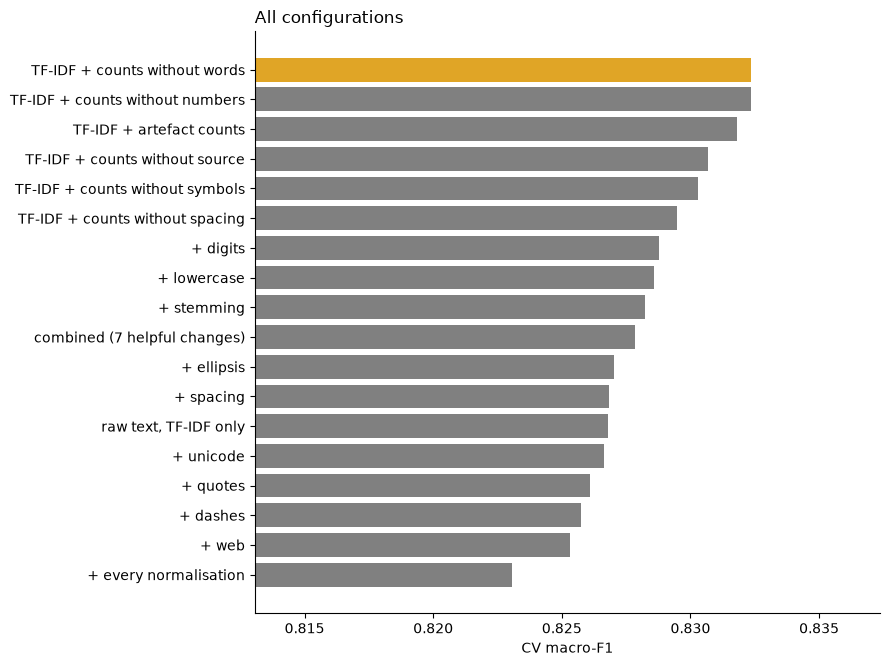

BASE_PARAMS from 'TF-IDF + counts without words' {'features__art__counts__groups': ('symbols', 'spacing', 'source', 'numbers')}


In [22]:
helpful = [n for n, r in norm_table.iterrows() if r.delta > 0 and r.all_folds_agree
           and n not in ('artefact counts only', '+ every normalisation')]
combined = {}
for name in helpful:
    combined |= norm_configs[name]
if any(n.startswith('TF-IDF + ') for n in helpful):
    combined.pop('features__art', None)
    dropped = [n.removeprefix('TF-IDF + counts without ') for n in helpful if 'without' in n]
    combined['features__art__counts__groups'] = tuple(g for g in ARTIFACTS if g not in dropped)

all_configs = dict(norm_configs)
if len(helpful) > 1:
    label = f'combined ({len(helpful)} helpful changes)'
    print('combined:', helpful)
    combo = run_search('search_normalisation_combined', lambda: grid_of({label: combined}), labels=[label])
    all_configs[label] = combined
    norm_results = pd.concat([norm_results, combo])
    norm_table = compare(norm_results, REF_NORM)

ranked = norm_table.drop(index='artefact counts only').sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(9, 0.32 * len(ranked) + 1))
ax.barh(ranked.index, ranked.macro_f1, color=[COLORS['fusion'] if n == ranked.index[-1] else 'gray' for n in ranked.index])
ax.set(xlim=(ranked.macro_f1.min() - 0.01, ranked.macro_f1.max() + 0.005), xlabel='CV macro-F1', title='All configurations')
plt.tight_layout()
plt.show()

BASE_PARAMS = all_configs[ranked.index[-1]]
print('BASE_PARAMS from', repr(ranked.index[-1]), BASE_PARAMS)

## C. Baseline

### C1. Vectoriser search

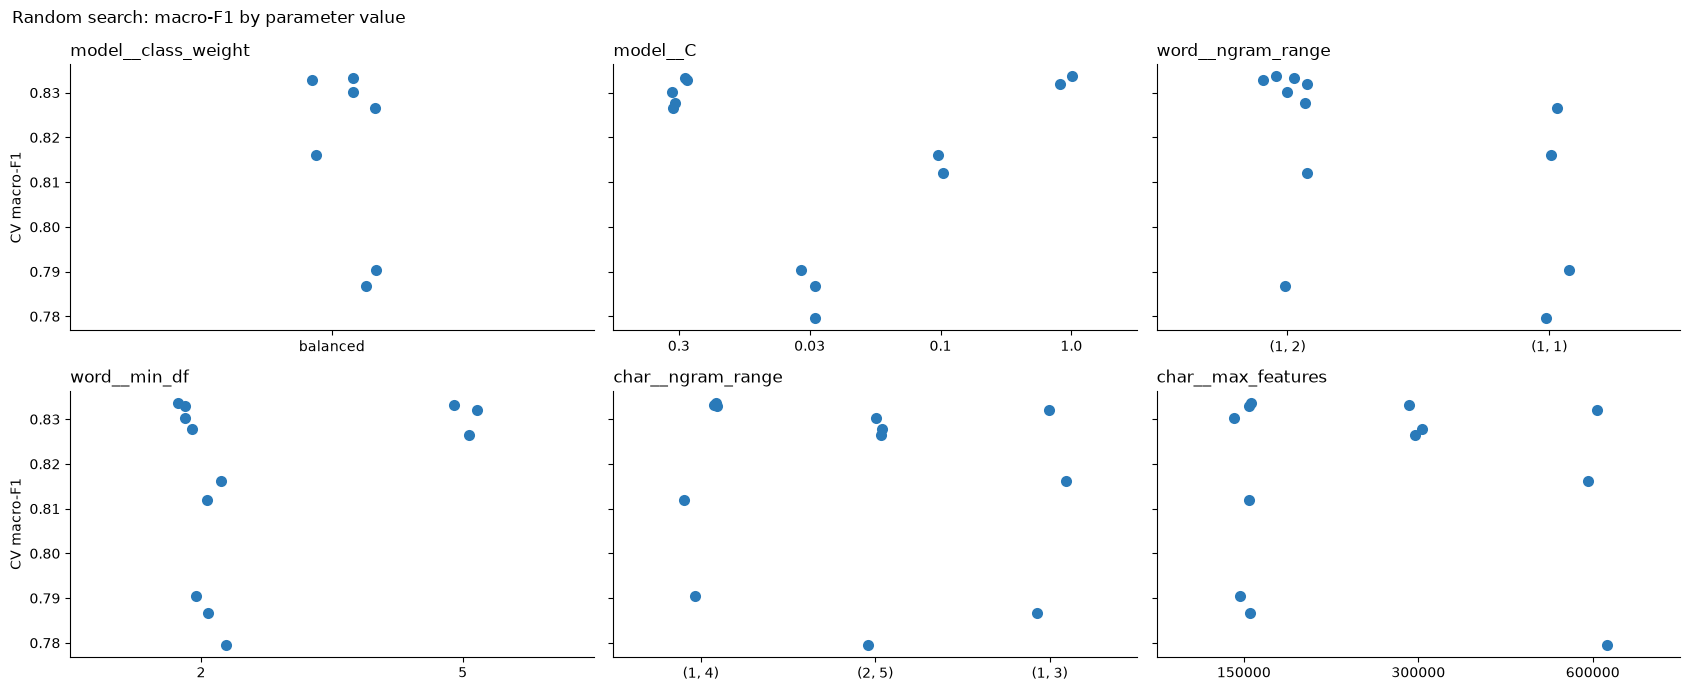

best CV macro-F1 0.8336: {'model__class_weight': None, 'model__C': 1.0, 'features__word__tfidf__ngram_range': (1, 2), 'features__word__tfidf__min_df': 2, 'features__char__ngram_range': (1, 4), 'features__char__max_features': 150000}


In [23]:
param_dist = {
    'features__char__ngram_range': [(1, 3), (1, 4), (2, 5)],
    'features__char__max_features': [150_000, 300_000, 600_000],
    'features__word__tfidf__ngram_range': [(1, 1), (1, 2)],
    'features__word__tfidf__min_df': [2, 5],
    'model__C': [0.03, 0.1, 0.3, 1.0],
    'model__class_weight': [None, 'balanced'],
}
vec_results = run_search('search_vectoriser', lambda: RandomizedSearchCV(
    make_text_model().set_params(**BASE_PARAMS), param_dist, n_iter=12, cv=search_cv, scoring=SCORING,
    refit=False, n_jobs=N_JOBS, random_state=SEED, error_score='raise'))

params = vec_results.params.map(ast.literal_eval).apply(pd.Series).rename(
    columns=lambda c: c.replace('features__', '').replace('tfidf__', ''))
vec = pd.concat([params.astype(str), vec_results[['mean_test_macro_f1', 'std_test_macro_f1']]], axis=1)

fig, axes = plt.subplots(2, 3, figsize=(17, 7), sharey=True)
for ax, col in zip(axes.flat, params.columns):
    sns.stripplot(data=vec, x=col, y='mean_test_macro_f1', color=COLORS['human'], size=8, ax=ax)
    ax.set(xlabel='', ylabel='CV macro-F1', title=col)
fig.suptitle('Random search: macro-F1 by parameter value', x=0.01, ha='left')
plt.tight_layout()
plt.show()

best_search = ast.literal_eval(vec_results.params[vec_results.mean_test_macro_f1.idxmax()])
VECTOR_PARAMS = {**BASE_PARAMS, **{k: v for k, v in best_search.items() if not k.startswith('model__')}}
SVC_PARAMS = {k.removeprefix('model__'): v for k, v in best_search.items() if k.startswith('model__')}
print(f'best CV macro-F1 {vec_results.mean_test_macro_f1.max():.4f}:', best_search)

### C2. Linear models

In [ ]:
class NBSVM(BaseEstimator, ClassifierMixin):
    def __init__(self, C=4.0, alpha=1.0):
        self.C = C
        self.alpha = alpha

    def fit(self, X, y):
        X, y = sparse.csr_matrix(X), np.asarray(y)
        self.classes_ = np.unique(y)
        self.ratios_, self.models_ = [], []
        for c in self.classes_:
            p = self.alpha + np.asarray(X[y == c].sum(0)).ravel()
            q = self.alpha + np.asarray(X[y != c].sum(0)).ravel()
            r = np.log((p / p.sum()) / (q / q.sum())).astype(np.float32)
            self.ratios_.append(r)
            self.models_.append(LogisticRegression(C=self.C, solver='liblinear').fit(X.multiply(r).tocsr(), y == c))
        return self

    def decision_function(self, X):
        X = sparse.csr_matrix(X)
        return np.column_stack([m.decision_function(X.multiply(r).tocsr()) for r, m in zip(self.ratios_, self.models_)])

    def predict(self, X):
        return self.classes_[self.decision_function(X).argmax(1)]


weights = SVC_PARAMS.get('class_weight')
LINEAR_MODELS = {
    'LinearSVC': LinearSVC(**SVC_PARAMS),
    'LogisticRegression': LogisticRegression(C=10, max_iter=2000, class_weight=weights),
    'SGD modified Huber': SGDClassifier(loss='modified_huber', alpha=2e-5, class_weight=weights, random_state=SEED),
    'ComplementNB': ComplementNB(alpha=0.3),
    'NB-SVM': NBSVM(C=4.0),
}
linear_configs = {name: {**VECTOR_PARAMS, 'model': model} for name, model in LINEAR_MODELS.items()}
linear_results = run_search('search_linear_models', lambda: grid_of(linear_configs), labels=list(linear_configs))

scores = linear_results[['mean_test_macro_f1'] + [f'mean_test_f1_{c}' for c in LABELS]]
scores.columns = ['macro'] + LABELS
fig, ax = plt.subplots(figsize=(12, 4))
scores.plot.bar(ax=ax, color=['black'] + palette, rot=0, width=0.8,
                yerr={'macro': linear_results.std_test_macro_f1.to_numpy()})
ax.set(ylim=(max(0, scores.min().min() - 0.05), 1), ylabel='CV F1', title='Linear models on the same features')
legend_headroom(ax)
plt.tight_layout()
plt.show()

BEST_LINEAR = linear_results.mean_test_macro_f1.idxmax()
print('best linear model:', BEST_LINEAR)

### C3. Baseline on val

In [ ]:
fit_rows = (train_df[~is_val] if FULL_TRAIN else train_part).set_index('id')
val_rows = val_part.set_index('id')
test_rows = test_df.set_index('id')
if SMOKE_TEST:
    test_rows = test_rows.head(500)
both_rows = pd.concat([fit_rows, val_rows])
all_ids = both_rows.index.union(test_rows.index)
y_val = val_rows.label
assert not set(fit_rows.prefix) & set(val_rows.prefix)
assert len(all_ids) == len(both_rows) + len(test_rows)
oof_cv = list(StratifiedGroupKFold(OOF_FOLDS, shuffle=True, random_state=SEED).split(
    fit_rows, fit_rows.label, groups=fit_rows.prefix))

RAM_GB = os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_PHYS_PAGES') / 2 ** 30
GB_PER_10K = 1.5
FIT_CAP = min(FIT_ROWS, int((RAM_GB - 10) / GB_PER_10K * 10_000))
PARALLEL_FITS = max(1, min(N_JOBS, int((RAM_GB - 10) // (GB_PER_10K * FIT_CAP / 10_000 + 1))))
CHUNK = 10_000
COLUMNS = ['text', 'lang', 'domain', 'label']
print(f'RAM {RAM_GB:.0f} GB: {PARALLEL_FITS} parallel fits of up to {FIT_CAP:,} rows, OOF on {len(fit_rows):,} rows')


def capped(rows, cap):
    return rows if cap is None or len(rows) <= cap else stratified_sample(rows, cap)


def fit_then_transform(fit_fn, transform_fn, train, apply):
    model = fit_fn(train)
    return pd.concat([transform_fn(model, apply.iloc[i:i + CHUNK]) for i in range(0, len(apply), CHUNK)])


def oof_features(name, fit_fn, transform_fn, cap=FIT_CAP, jobs=None, **params):
    # 5 OOF folds + one model on all fit rows for val and test; every task is its own shard
    rows = fit_rows[COLUMNS]

    def make_args(k):
        if k < len(oof_cv):
            tr, te = oof_cv[k]
            return capped(rows.iloc[tr], cap), rows.iloc[te]
        return capped(rows, cap), pd.concat([val_rows[COLUMNS], test_rows[COLUMNS[:-1]]])

    feats = sharded(f'feat_{name}_{TAG}.csv', partial(fit_then_transform, fit_fn, transform_fn), make_args,
                    len(oof_cv) + 1, jobs or PARALLEL_FITS, cap=cap, folds=OOF_FOLDS, fit_rows=len(fit_rows),
                    seed=SEED, **params)
    assert feats.index.is_unique and feats.index.sort_values().equals(all_ids.sort_values())
    return feats


def fit_linear(rows):
    model = make_text_model(LINEAR_MODELS[BEST_LINEAR]).set_params(**VECTOR_PARAMS)
    return model.fit(rows[['text', 'lang']], rows.label)


def linear_scores(model, rows):
    X = rows[['text', 'lang']]
    scores = model.decision_function(X) if hasattr(model, 'decision_function') else model.predict_log_proba(X)
    return pd.DataFrame(scores, index=rows.index, columns=[f'lin_{c}' for c in model.classes_])


linear_feats = oof_features('linear', fit_linear, linear_scores, model=BEST_LINEAR, vectoriser=VECTOR_PARAMS)

In [ ]:
experiment_log, val_predictions = {}, {}
REFERENCE = f'C3 baseline: {BEST_LINEAR} on char 1-4 + word 1-2 TF-IDF'


def to_label(scores):
    return scores.columns.str.split('_').str[-1].to_numpy()[scores.to_numpy().argmax(1)]


def evaluate(step, pred):
    val_predictions[step] = pd.Series(np.asarray(pred), index=val_rows.index)
    experiment_log[step] = {'macro_f1': f1_score(y_val, pred, average='macro'),
                            **{f'f1_{c}': class_f1(y_val, pred, c) for c in LABELS}}
    pd.DataFrame(experiment_log).T.to_csv(Path(RUNS) / f'experiment_log_{TAG}.csv')
    scores = experiment_log[step]
    log.info(f"RESULT {step}: macro-F1 {scores['macro_f1']:.4f} | "
             + ', '.join(f"{c} {scores[f'f1_{c}']:.4f}" for c in LABELS))


def per_domain(steps):
    return pd.DataFrame({s: val_rows.assign(pred=val_predictions[s]).groupby('domain')[['label', 'pred']].apply(
        lambda g: f1_score(g.label, g.pred, average='macro')) for s in steps})


def plot_confusions(steps):
    fig, axes = plt.subplots(1, len(steps), figsize=(5 * len(steps), 4))
    for ax, step in zip(np.atleast_1d(axes), steps):
        cm = confusion_matrix(y_val, val_predictions[step], labels=LABELS, normalize='true')
        sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False,
                    xticklabels=LABELS, yticklabels=LABELS, ax=ax)
        ax.set(xlabel='predicted', ylabel='true', title=step)
    plt.tight_layout()
    plt.show()


evaluate(REFERENCE, to_label(linear_feats.loc[val_rows.index]))
print(classification_report(y_val, val_predictions[REFERENCE], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 1.6]})
cm = confusion_matrix(y_val, val_predictions[REFERENCE], labels=LABELS, normalize='true')
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=LABELS,
            yticklabels=LABELS, ax=axes[0])
axes[0].set(xlabel='predicted', ylabel='true', title='Baseline confusion matrix')
per_domain([REFERENCE])[REFERENCE].sort_values().plot.barh(ax=axes[1], color=COLORS['human'], xlim=(0, 1),
                                                           title='Baseline macro-F1 by domain')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

## D. Experiments

### D1. Segment profile

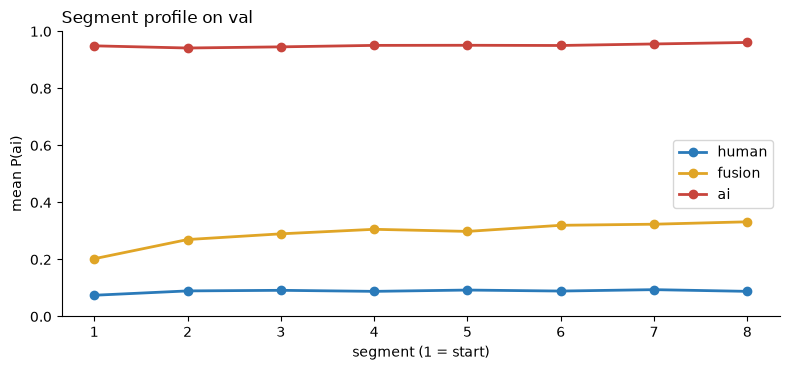

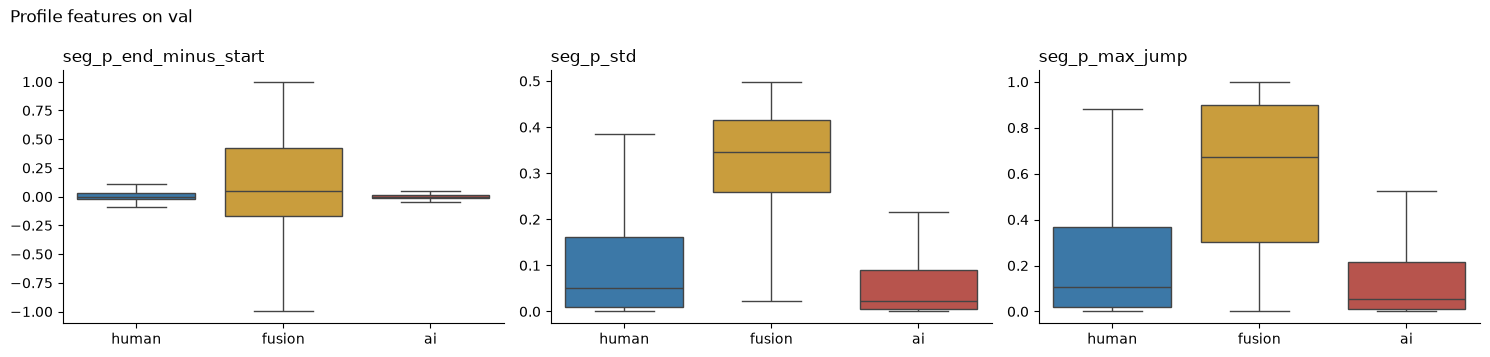

In [27]:
N_SEGMENTS = 8


def split_segments(text, k=N_SEGMENTS):
    return [' '.join(part) for part in np.array_split(text.split(), k)]


def fit_segment_model(rows):
    two = rows[rows.label != 'fusion']
    segments = [s for t in two.text for s in split_segments(t)]
    model = make_pipeline(
        TfidfVectorizer(analyzer='char', ngram_range=(1, 4), min_df=3, max_features=300_000, sublinear_tf=True,
                        lowercase=False, dtype=np.float32),
        LogisticRegression(C=4, max_iter=1000))
    return model.fit(segments, np.repeat((two.label == 'ai').to_numpy(), N_SEGMENTS))


def profile_features(p, prefix):
    f = pd.DataFrame(p, columns=[f'{prefix}{k + 1}' for k in range(N_SEGMENTS)])
    jumps = np.diff(p, axis=1)
    f[f'{prefix}_mean'] = p.mean(1)
    f[f'{prefix}_std'] = p.std(1)
    f[f'{prefix}_end_minus_start'] = p[:, -3:].mean(1) - p[:, :2].mean(1)
    f[f'{prefix}_range'] = p.max(1) - p.min(1)
    f[f'{prefix}_max_jump'] = jumps.max(1)
    f[f'{prefix}_max_jump_at'] = jumps.argmax(1) / N_SEGMENTS
    return f


def segment_profile(model, rows):
    segments = [s for t in rows.text for s in split_segments(t)]
    p = model.predict_proba(segments)[:, 1].reshape(len(rows), N_SEGMENTS)
    return profile_features(p, 'seg_p').set_index(rows.index)


segment_feats = oof_features('segments', fit_segment_model, segment_profile)
val_segments = segment_feats.loc[val_rows.index].assign(label=y_val)

fig, ax = plt.subplots(figsize=(8, 3.8))
profile = val_segments.filter(regex=r'^seg_p\d+$').groupby(y_val).mean()
for label in LABELS:
    ax.plot(range(1, N_SEGMENTS + 1), profile.loc[label], marker='o', lw=2, color=COLORS[label], label=label)
ax.set(xlabel='segment (1 = start)', ylabel='mean P(ai)', ylim=(0, 1), title='Segment profile on val')
ax.legend()
plt.tight_layout()
plt.show()
plot_by_class(val_segments, ['seg_p_end_minus_start', 'seg_p_std', 'seg_p_max_jump'], 'Profile features on val')

### D1b. Sentence classifier + change point

In [ ]:
SENT_SPLIT = re.compile(r'(?<=[.!?])\s+')
SENT_FIT_CAP = 400_000  # sentences per fit
SENT_FEATURES = ['sent_mean', 'sent_std', 'sent_first', 'sent_last', 'sent_max', 'sent_share_ai', 'sent_boundary',
                 'sent_contrast', 'sent_fit', 'sent_log_count']
boundary_by_id = boundary.set_index('id').char  # train only: char offset where the AI part of a fusion text starts


def split_sentences(text):
    cuts = [0] + [m.end() for m in SENT_SPLIT.finditer(text)]
    return [(s, text[s:e].strip()) for s, e in zip(cuts, cuts[1:] + [len(text)])]


def change_point(p):
    # best single step from human (0) to AI (1), found exactly with cumulative sums:
    # (position / n, mean after - mean before, 1 - cost / n)
    n = len(p)
    if n == 0:
        return 0.0, 0.0, 0.0
    c = np.concatenate([[0.0], np.cumsum(p)])
    k = np.arange(n + 1)
    cost = c + (n - k) - (c[-1] - c)
    best = int(cost.argmin())
    before = p[:best].mean() if best > 0 else 0.0
    after = p[best:].mean() if best < n else 1.0
    return best / n, after - before, 1 - cost[best] / n


def sentence_training_set(rows):
    # human sentences = 0, ai sentences = 1; fusion sentences fully before / after the known boundary = 0 / 1,
    # the sentence that contains the boundary and fusion rows without a human source are left out
    texts, ys = [], []
    for text, label, b in zip(rows.text, rows.label, boundary_by_id.reindex(rows.index).to_numpy(float)):
        if label == 'fusion' and np.isnan(b):
            continue
        sents = split_sentences(text)
        ends = [s for s, _ in sents[1:]] + [len(text)]
        for (s, sent), e in zip(sents, ends):
            y = 1 if label == 'ai' or (label == 'fusion' and s >= b) else 0 if label == 'human' or e <= b else None
            if y is not None and sent:
                texts.append(sent)
                ys.append(y)
    return texts, np.array(ys)


def fit_sentence_model(rows):
    texts, y = sentence_training_set(rows)
    if len(texts) > SENT_FIT_CAP:
        keep = np.random.default_rng(SEED).choice(len(texts), SENT_FIT_CAP, replace=False)
        texts, y = [texts[i] for i in keep], y[keep]
    model = make_pipeline(
        TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 4), min_df=3, max_features=300_000, sublinear_tf=True,
                        lowercase=False, dtype=np.float32),
        LogisticRegression(C=2, max_iter=1000))
    return model.fit(texts, y)


def sentence_profile(model, rows):
    sents = [split_sentences(t) for t in rows.text]
    p = model.predict_proba([s for ss in sents for _, s in ss])[:, 1]
    out, pos = np.zeros((len(rows), len(SENT_FEATURES)), np.float32), 0
    for i, ss in enumerate(sents):
        q = p[pos:pos + len(ss)]
        pos += len(ss)
        out[i] = [q.mean(), q.std(), q[0], q[-1], q.max(), (q > 0.5).mean(), *change_point(q), np.log(len(q))]
    return pd.DataFrame(out, index=rows.index, columns=SENT_FEATURES)


sentence_feats = oof_features('sentences', fit_sentence_model, sentence_profile, sent_cap=SENT_FIT_CAP)
plot_by_class(sentence_feats.loc[val_rows.index].assign(label=y_val), ['sent_contrast', 'sent_boundary', 'sent_fit'],
              'Sentence classifier + change point on val')

### D2. Character n-gram language models

feat_char_lm_full.csv: 4.0 min


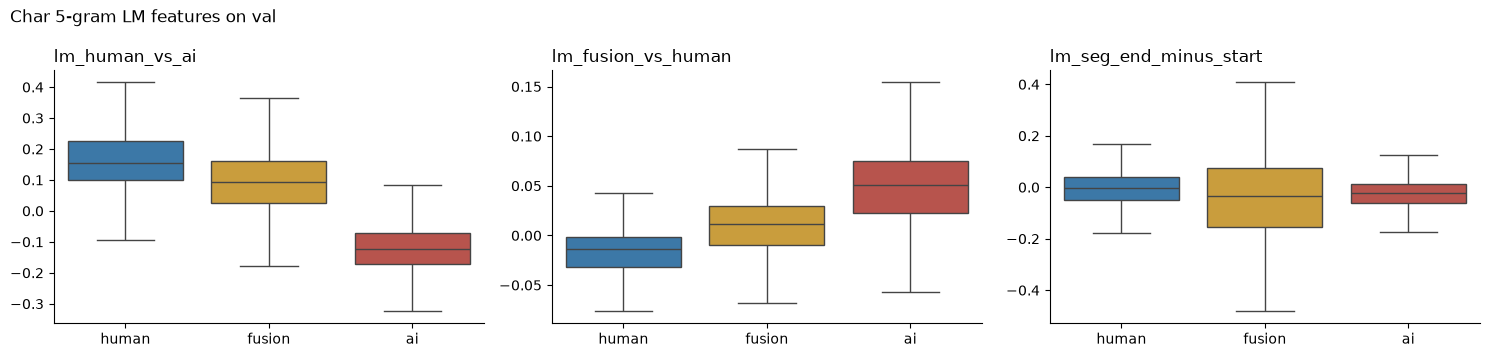

In [28]:
LM_N, LM_K, LM_ALPHABET, LM_BUCKETS = 5, 0.1, 300, 2 ** 22
LM_ORDERS = (LM_N, LM_N - 1)


def hash_ngrams(texts, n):
    return HashingVectorizer(analyzer='char', ngram_range=(n, n), lowercase=False, alternate_sign=False, norm=None,
                             n_features=LM_BUCKETS, dtype=np.float32).transform(texts)


def class_ngram_counts(rows):
    counts = np.zeros((len(LABELS), len(LM_ORDERS), LM_BUCKETS))
    for i, c in enumerate(LABELS):
        texts = rows.text[rows.label == c].tolist()
        for start in range(0, len(texts), 5_000):
            for j, n in enumerate(LM_ORDERS):
                counts[i, j] += np.asarray(hash_ngrams(texts[start:start + 5_000], n).sum(0)).ravel()
    return counts


def log_tables(counts):
    return np.stack([np.log(counts[:, 0] + LM_K), np.log(counts[:, 1] + LM_K * LM_ALPHABET)], 1).astype(np.float32)


def lm_loglik(texts, tables):
    ngrams = hash_ngrams(texts, LM_N)
    ll = ngrams @ tables[:, 0].T - hash_ngrams(texts, LM_N - 1) @ tables[:, 1].T
    return ll / np.maximum(np.asarray(ngrams.sum(1)).ravel(), 1)[:, None]


def char_lm_chunk(rows, tables):
    h, f, a = (LABELS.index(c) for c in ('human', 'fusion', 'ai'))
    texts = rows.text.tolist()
    doc = lm_loglik(texts, tables)
    seg = lm_loglik([s for t in texts for s in split_segments(t)], tables).reshape(len(rows), N_SEGMENTS, -1)
    out = profile_features(seg[:, :, h] - seg[:, :, a], 'lm_seg')
    out['lm_human_vs_ai'] = doc[:, h] - doc[:, a]
    out['lm_fusion_vs_ai'] = doc[:, f] - doc[:, a]
    out['lm_fusion_vs_human'] = doc[:, f] - doc[:, h]
    out['lm_ai_loglik'] = doc[:, a]
    return out.set_index(rows.index)


def char_lm_all():
    folds = [fit_rows.iloc[te][['text', 'label']] for _, te in oof_cv]
    fold_counts = Parallel(n_jobs=N_JOBS)(delayed(class_ngram_counts)(rows) for rows in folds)
    total = np.sum(fold_counts, axis=0)
    jobs = [(rows[['text']], log_tables(total - counts)) for rows, counts in zip(folds, fold_counts)]
    jobs.append((pd.concat([val_rows, test_rows])[['text']], log_tables(total)))
    del fold_counts, total
    return pd.concat(Parallel(n_jobs=N_JOBS)(delayed(char_lm_chunk)(rows.iloc[i:i + CHUNK], tables)
                                             for rows, tables in jobs for i in range(0, len(rows), CHUNK)))


char_lm_feats = cached(f'feat_char_lm_{TAG}.csv', char_lm_all)
assert char_lm_feats.index.is_unique and char_lm_feats.index.sort_values().equals(all_ids.sort_values())
plot_by_class(char_lm_feats.loc[val_rows.index].assign(label=y_val),
              ['lm_human_vs_ai', 'lm_fusion_vs_human', 'lm_seg_end_minus_start'], 'Char 5-gram LM features on val')

### D3. Compression and dense features

feat_dense_full.csv: 1.5 min


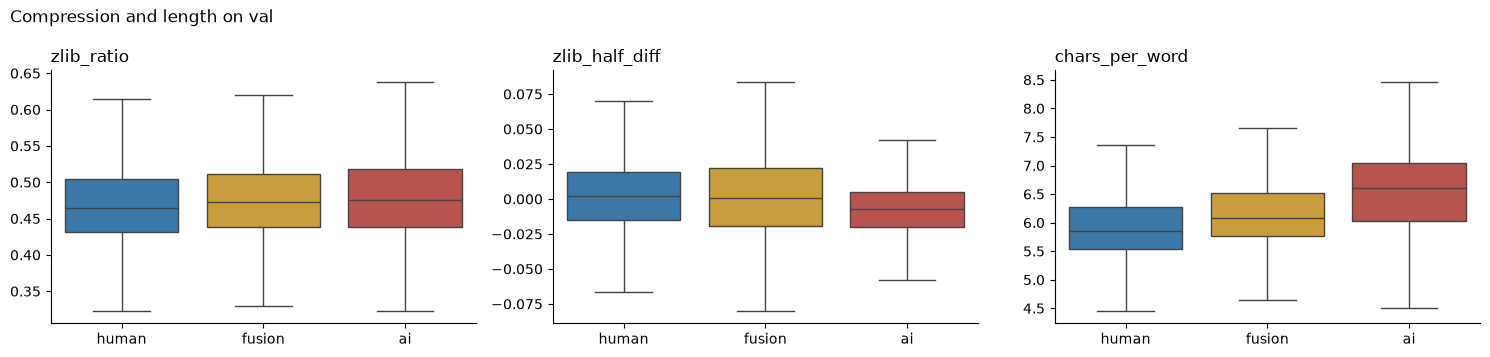

In [29]:
def compression_ratio(text):
    data = text.encode()
    return len(zlib.compress(data, 9)) / len(data)


def dense_features(rows):
    chars, words = rows.text.str.len(), rows.text.str.split().str.len()
    first = rows.text.map(lambda t: compression_ratio(t[:len(t) // 2]))
    second = rows.text.map(lambda t: compression_ratio(t[len(t) // 2:]))
    f = pd.DataFrame({'log_chars': np.log(chars), 'log_words': np.log(words), 'chars_per_word': chars / words,
                      'is_de': (rows.lang == 'de-DE').astype(int), 'zlib_ratio': rows.text.map(compression_ratio),
                      'zlib_first_half': first, 'zlib_second_half': second, 'zlib_half_diff': second - first},
                     index=rows.index)
    art = count_artifacts(rows.text).div(chars, axis=0).mul(1000).add_prefix('art_')
    domains = pd.get_dummies(rows.domain, prefix='domain', dtype=int).reindex(
        columns=[f'domain_{d}' for d in DOMAINS], fill_value=0)
    return pd.concat([f, art, domains], axis=1)


DOMAINS = sorted(train_df.domain.unique())
dense_rows = pd.concat([both_rows, test_rows])[['text', 'lang', 'domain']]
dense = cached(f'feat_dense_{TAG}.csv', lambda: pd.concat(Parallel(n_jobs=N_JOBS)(
    delayed(dense_features)(dense_rows.iloc[i:i + CHUNK]) for i in range(0, len(dense_rows), CHUNK))))
plot_by_class(dense.loc[val_rows.index].assign(label=y_val), ['zlib_ratio', 'zlib_half_diff', 'chars_per_word'],
              'Compression and length on val')

### D3b. Stylometry and Burrows Delta

In [ ]:
VOWELS = re.compile(r'[aeiouyäöü]+', re.I)
STRIP = '.,;:!?"()„“”'
STYLE_COLUMNS = ['sty_sent_len', 'sty_sent_len_std', 'sty_sent_len_cv', 'sty_sent_len_max', 'sty_word_len',
                 'sty_word_len_std', 'sty_syllables_per_word', 'sty_readability', 'sty_yule_k', 'sty_hapax',
                 'sty_mattr', 'sty_mattr_second_minus_first', 'sty_sent_len_second_minus_first', 'sty_function_words']
DELTA_WORDS = 150


def text_style(text, lang):
    words = text.split()
    n = max(len(words), 1)
    lower = [w.strip(STRIP).lower() for w in words]
    sl = np.array([len(s.split()) for s in SENT_SPLIT.split(text) if s.strip()] or [n])
    wl = np.array([len(w) for w in lower] or [0])
    syllables = sum(max(1, len(VOWELS.findall(w))) for w in lower) / n
    # Flesch reading ease (EN) and Amstad's German version (DE)
    readability = (206.835 - 1.015 * sl.mean() - 84.6 * syllables if lang == 'en-EN'
                   else 180 - sl.mean() - 58.5 * syllables)
    counts = Counter(lower)
    yule = 1e4 * (sum(m * m * v for m, v in Counter(counts.values()).items()) - n) / (n * n)
    mattr = [len(set(w)) / max(len(w), 1) for w in (lower[i:i + 50] for i in range(0, max(n - 49, 1), 25))]
    half_m, half_s = len(mattr) // 2, len(sl) // 2
    return [sl.mean(), sl.std(), sl.std() / max(sl.mean(), 1), sl.max(), wl.mean(), wl.std(), syllables, readability,
            yule, sum(v == 1 for v in counts.values()) / max(len(counts), 1), np.mean(mattr),
            np.mean(mattr[half_m:]) - np.mean(mattr[:max(half_m, 1)]),
            sl[half_s:].mean() - sl[:half_s].mean() if half_s else 0.0,
            sum(w in FUNCTION_WORDS.get(lang, ()) for w in lower) / n]


def word_freqs(texts, vocab):
    X = CountVectorizer(vocabulary=vocab, token_pattern=r'(?u)\b\w+\b').transform(texts).toarray()
    return X / np.maximum(texts.str.split().str.len().to_numpy(), 1)[:, None]


def fit_delta(rows):
    # Burrows' Delta: z-scored frequencies of the most frequent words, one centroid per class (per language)
    model = {}
    for lang, part in rows.groupby('lang'):
        vocab = CountVectorizer(token_pattern=r'(?u)\b\w+\b', max_features=DELTA_WORDS).fit(
            part.text).get_feature_names_out()
        F = word_freqs(part.text, vocab)
        mu, sd = F.mean(0), F.std(0) + 1e-6
        Z = (F - mu) / sd
        model[lang] = vocab, mu, sd, {c: Z[(part.label == c).to_numpy()].mean(0) for c in LABELS}
    return model


def stylometry(model, rows):
    out = pd.DataFrame([text_style(t, l) for t, l in zip(rows.text, rows.lang)], index=rows.index,
                       columns=STYLE_COLUMNS)
    delta = np.zeros((len(rows), len(LABELS)), np.float32)
    for lang in rows.lang.unique():
        if lang in model:
            m = (rows.lang == lang).to_numpy()
            vocab, mu, sd, centroids = model[lang]
            z = (word_freqs(rows.text[m], vocab) - mu) / sd
            delta[m] = np.stack([np.nan_to_num(np.abs(z - centroids[c]).mean(1)) for c in LABELS], 1)
    for j, c in enumerate(LABELS):
        out[f'delta_{c}'] = delta[:, j]
    out['delta_human_minus_ai'] = out.delta_human - out.delta_ai
    out['delta_fusion_minus_human'] = out.delta_fusion - out.delta_human
    return out


stylo_feats = oof_features('stylometry', fit_delta, stylometry, delta_words=DELTA_WORDS)
plot_by_class(stylo_feats.loc[val_rows.index].assign(label=y_val),
              ['delta_human_minus_ai', 'sty_sent_len_cv', 'sty_mattr_second_minus_first'], 'Stylometry on val')

### D3c. Compression with class dictionaries

In [ ]:
ZDICT_BYTES, ZDICT_DOCS = 32_768, 5_000


def fit_zdicts(rows):
    # one zlib preset dictionary per language and class: its most frequent word 2-3-grams, the most frequent last
    dicts = {}
    for (lang, label), part in rows.groupby(['lang', 'label']):
        sample = part.text.sample(min(len(part), ZDICT_DOCS), random_state=SEED)
        vec = CountVectorizer(ngram_range=(2, 3), token_pattern=r'\S+', lowercase=False, min_df=min(5, len(sample)),
                              dtype=np.int32)
        counts = np.asarray(vec.fit_transform(sample).sum(0)).ravel()
        terms = vec.get_feature_names_out()[np.argsort(counts, kind='stable')[-5_000:]]
        dicts[lang, label] = ' '.join(terms).encode()[-ZDICT_BYTES:]
    return dicts


def compressed_size(data, zdict=None):
    c = zlib.compressobj(6, zdict=zdict) if zdict else zlib.compressobj(6)
    return len(c.compress(data)) + len(c.flush())


def zdict_features(dicts, rows):
    # bytes saved by each class dictionary: text that looks like a class compresses better with its dictionary
    parts = ('all', 'second_half')
    out = np.zeros((len(rows), len(parts) * len(LABELS)), np.float32)
    for r, (text, lang) in enumerate(zip(rows.text, rows.lang)):
        for p, part in enumerate((text, text[len(text) // 2:])):
            data = part.encode()
            base = compressed_size(data)
            for j, c in enumerate(LABELS):
                if (lang, c) in dicts:
                    out[r, p * len(LABELS) + j] = (base - compressed_size(data, dicts[lang, c])) / base
    f = pd.DataFrame(out, index=rows.index, columns=[f'zd_{p}_{c}' for p in parts for c in LABELS])
    for p in parts:
        f[f'zd_{p}_human_minus_ai'] = f[f'zd_{p}_human'] - f[f'zd_{p}_ai']
        f[f'zd_{p}_fusion_minus_human'] = f[f'zd_{p}_fusion'] - f[f'zd_{p}_human']
    return f


zdict_feats = oof_features('zdict', fit_zdicts, zdict_features, dict_bytes=ZDICT_BYTES, dict_docs=ZDICT_DOCS)
plot_by_class(zdict_feats.loc[val_rows.index].assign(label=y_val),
              ['zd_all_human_minus_ai', 'zd_second_half_human_minus_ai', 'zd_all_fusion_minus_human'],
              'Class-dictionary compression on val')

### D4. LM perplexity (GPU)

In [ ]:
def token_ids(tokenizer, texts, transform):
    out = []
    for start in range(0, len(texts), CHUNK):
        ids = tokenizer(texts[start:start + CHUNK], add_special_tokens=False).input_ids
        out += [np.asarray(transform(x), np.int32) for x in ids]
    return out


def make_batches(seqs, batch_size, pad, shuffle=False, seed=SEED):
    lengths = np.fromiter(map(len, seqs), int, len(seqs))
    order = np.random.default_rng(seed).permutation(len(seqs)) if shuffle else np.argsort(lengths)
    for start in range(0, len(order), batch_size):
        idx = order[start:start + batch_size]
        ids = torch.full((len(idx), lengths[idx].max()), pad, dtype=torch.long)
        mask = torch.zeros_like(ids)
        for row, i in enumerate(idx):
            ids[row, :lengths[i]] = torch.from_numpy(seqs[i])
            mask[row, :lengths[i]] = 1
        yield idx, ids, mask


_LM = {}


def load_lm(device=DEVICE):
    if not _LM:
        _LM['tokenizer'] = AutoTokenizer.from_pretrained(LM_NAME)
        _LM['model'] = AutoModelForCausalLM.from_pretrained(LM_NAME, dtype=torch.bfloat16).to(device).eval()
    return _LM['tokenizer'], _LM['model']


def perplexity_features(rows, device=DEVICE):
    tokenizer, model = load_lm(device)
    pad = tokenizer.pad_token_id if tokenizer.pad_token_id is not None else 0
    half = LM_MAX_TOKENS // 2
    ids = token_ids(tokenizer, rows.text.tolist(), lambda x: x if len(x) <= LM_MAX_TOKENS else x[:half] + x[-half:])
    out = np.zeros((len(ids), 4 + 2 * N_SEGMENTS), np.float32)
    for batch, input_ids, mask in progress(make_batches(ids, LM_BATCH, pad), total=-(-len(ids) // LM_BATCH),
                                       desc='perplexity'):
        with torch.inference_mode():
            input_ids = input_ids.to(device)
            logits = model(input_ids=input_ids, attention_mask=mask.to(device)).logits[:, :-1]
            logp = torch.log_softmax(logits.float(), -1)
            del logits
            token_lp = logp.gather(-1, input_ids[:, 1:, None])[..., 0].cpu().numpy()
            entropy = -logp.exp().mul_(logp).sum(-1).cpu().numpy()
            del logp
        for row, i in enumerate(batch):
            n = len(ids[i]) - 1
            lp, ent = token_lp[row, :n], entropy[row, :n]
            out[i] = [lp.mean(), lp.std(), ent.mean(), lp.mean() + ent.mean(),
                      *[s.mean() for s in np.array_split(lp, N_SEGMENTS)],
                      *[s.mean() for s in np.array_split(ent, N_SEGMENTS)]]
    columns = (['ppl_logprob', 'ppl_logprob_std', 'ppl_entropy', 'ppl_logprob_plus_entropy']
               + [f'ppl_seg_lp{k + 1}' for k in range(N_SEGMENTS)] + [f'ppl_seg_ent{k + 1}' for k in range(N_SEGMENTS)])
    f = pd.DataFrame(out, index=rows.index, columns=columns)
    seg_lp = f.filter(regex=r'^ppl_seg_lp').to_numpy()
    f['ppl_seg_end_minus_start'] = seg_lp[:, -3:].mean(1) - seg_lp[:, :2].mean(1)
    return f


PPL_SHARD = 8192
ppl_file = Path(RUNS) / f'feat_perplexity_{TAG}.csv'
ppl_feats = read_frame(ppl_file) if ppl_file.exists() else None
if RUN_PERPLEXITY:
    # shards of similar length (less padding), each saved as soon as it is done
    ppl_rows = pd.concat([both_rows, test_rows])[['text']]
    by_length = ppl_rows.index[np.argsort(ppl_rows.text.str.len().to_numpy(), kind='stable')]
    ppl_feats = sharded(ppl_file.name, perplexity_features,
                        lambda k: (ppl_rows.loc[by_length[k * PPL_SHARD:(k + 1) * PPL_SHARD]],),
                        -(-len(ppl_rows) // PPL_SHARD), n_jobs=1, model=LM_NAME, max_tokens=LM_MAX_TOKENS)
    _LM.clear()
    free_gpu()
if ppl_feats is None:
    print('skipped: RUN_PERPLEXITY = False')
else:
    plot_by_class(ppl_feats.loc[val_rows.index].assign(label=y_val),
                  ['ppl_logprob', 'ppl_logprob_plus_entropy', 'ppl_seg_end_minus_start'], f'{LM_NAME} on val')

### D5. fastText

In [ ]:
try:
    import fasttext
except ImportError:
    fasttext = None


def fit_fasttext(rows):
    file = Path(RUNS) / f'fasttext_{uuid.uuid4().hex}.txt'
    file.write_text(''.join(f'__label__{label} {text}\n' for label, text in zip(rows.label, rows.text)))
    model = fasttext.train_supervised(str(file), minn=2, maxn=5, wordNgrams=2, dim=100, epoch=10, lr=0.5,
                                      verbose=0, seed=SEED)
    file.unlink()
    return model


def fasttext_features(model, rows):
    labels, probs = model.predict(rows.text.tolist(), k=len(LABELS))
    out = pd.DataFrame([dict(zip(ls, ps)) for ls, ps in zip(labels, probs)], index=rows.index)
    return out.rename(columns=lambda c: 'ft_' + c.removeprefix('__label__'))[[f'ft_{c}' for c in LABELS]]


ft_file = Path(RUNS) / f'feat_fasttext_{TAG}.csv'
ft_feats = None
if fasttext is not None or ft_file.exists():
    ft_feats = oof_features('fasttext', fit_fasttext, fasttext_features, cap=None, jobs=1)
    evaluate('D5 fastText: char 2-5 + word bigrams', to_label(ft_feats.loc[val_rows.index]))
else:
    print('skipped: fasttext is not installed')

### D6. Stacking

In [ ]:
LGB_PARAMS = dict(n_estimators=3000, learning_rate=0.03, num_leaves=63, min_child_samples=40, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=os.cpu_count(),
                  verbose=-1)
# added one at a time in this order; every group except the Qwen one is classical NLP
FEATURE_GROUPS = {name: f for name, f in {
    'NB-SVM scores': linear_feats,
    'length, artefact rates, domain': dense.drop(columns=dense.filter(like='zlib').columns),
    'zlib compression ratio': dense.filter(like='zlib'),
    'class-dictionary compression': zdict_feats,
    'stylometry + Burrows Delta': stylo_feats,
    'segment profile (8 parts)': segment_feats,
    'sentence classifier + change point': sentence_feats,
    'char 5-gram LMs': char_lm_feats,
    'fastText': ft_feats,
    'Qwen2.5-0.5B perplexity': ppl_feats,
}.items() if f is not None}
CLASSICAL_GROUPS = [g for g in FEATURE_GROUPS if not g.startswith('Qwen')]
GROUP_HASH = {g: int(pd.util.hash_pandas_object(f).sum()) for g, f in FEATURE_GROUPS.items()}


def stack_matrix(groups, rows):
    return pd.concat([FEATURE_GROUPS[g].loc[rows.index] for g in groups], axis=1)


def fit_lgb(X, y):
    tr, te = oof_cv[0]
    probe = lgb.LGBMClassifier(**LGB_PARAMS).fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[te], y.iloc[te])],
                                                 callbacks=[lgb.early_stopping(100, verbose=False)])
    log.info(f'stack: {X.shape[1]} features, early stopping at {probe.best_iteration_} trees, refit on {len(X):,} rows')
    return lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': probe.best_iteration_}).fit(X, y)


def run_stack(step, groups):
    model = cached_object(f'stack_{params_key(groups)}_{TAG}', lambda: fit_lgb(stack_matrix(groups, fit_rows),
                                                                               fit_rows.label),
                          groups=groups, data=[GROUP_HASH[g] for g in groups], lgb=LGB_PARAMS, folds=OOF_FOLDS)
    evaluate(step, model.predict(stack_matrix(groups, val_rows)))
    return model


stack_steps = []
for i, name in enumerate(FEATURE_GROUPS):
    step = f'D6 stack (LightGBM): {name}' if i == 0 else f'D6 stack: + {name}'
    stack_model = run_stack(step, list(FEATURE_GROUPS)[:i + 1])
    stack_steps.append(step)
run_stack('D6 stack: classical groups without NB-SVM scores', [g for g in CLASSICAL_GROUPS if g != 'NB-SVM scores'])
FINAL_GROUPS = CLASSICAL_GROUPS  # the level-1 stack is classical NLP only; transformers join in level-2
if FINAL_GROUPS != list(FEATURE_GROUPS):
    stack_model = run_stack('D6 stack: classical groups only (final level-1)', FINAL_GROUPS)

progress = pd.DataFrame(experiment_log).T.loc[[REFERENCE] + stack_steps]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(progress.index, progress.macro_f1, color='black', marker='o', lw=2.5, label='macro')
for c in LABELS:
    ax.plot(progress.index, progress[f'f1_{c}'], color=COLORS[c], marker='o', lw=1.5, label=c)
ax.axhline(progress.macro_f1.iloc[0], color='gray', ls=':', lw=1)
ax.set(ylabel='val F1', title='Adding one feature group at a time')
ax.tick_params(axis='x', rotation=25)
plt.setp(ax.get_xticklabels(), ha='right')
legend_right(ax)
plt.tight_layout()
plt.show()

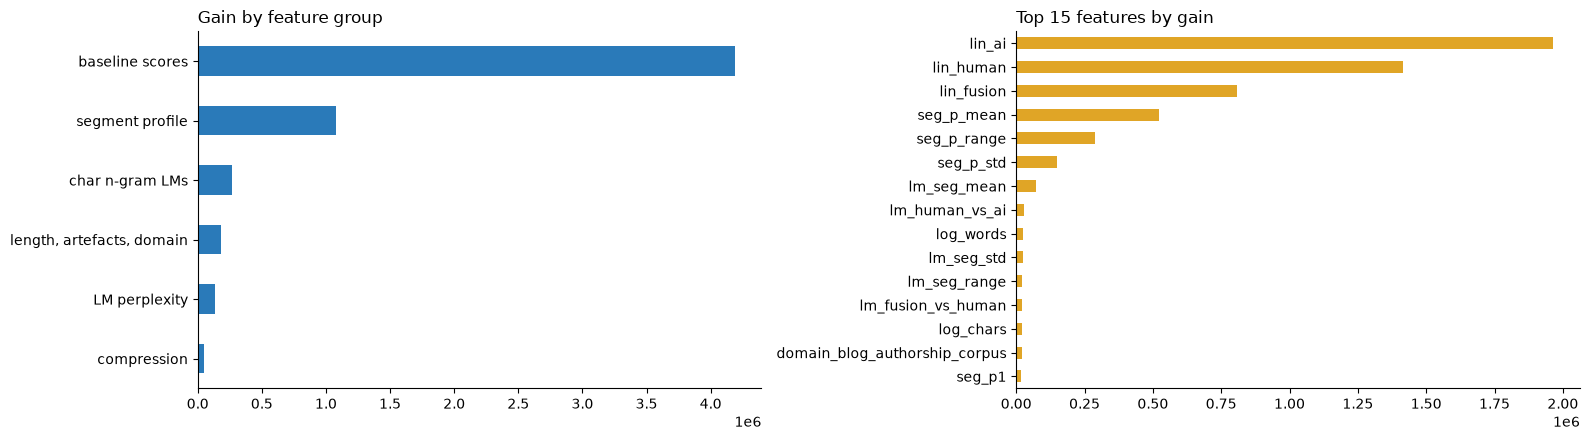

In [34]:
columns = stack_matrix(FINAL_GROUPS, val_rows.iloc[:1]).columns
group_of = {col: g for g in FINAL_GROUPS for col in FEATURE_GROUPS[g].columns}
gain = pd.Series(stack_model.booster_.feature_importance('gain'), index=columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
gain.groupby(group_of).sum().sort_values().plot.barh(ax=axes[0], color=COLORS['human'], title='Gain by feature group')
gain.nlargest(15).sort_values().plot.barh(ax=axes[1], color=COLORS['fusion'], title='Top 15 features by gain')
plt.tight_layout()
plt.show()

### D7. Class offsets for macro-F1

In [ ]:
def apply_offsets(proba, offsets):
    return np.array(LABELS)[(np.log(proba + 1e-9) + offsets).argmax(1)]


def stack_oof():
    X_fit = stack_matrix(FINAL_GROUPS, fit_rows)
    out = np.zeros((len(fit_rows), len(LABELS)))
    for tr, te in oof_cv:
        model = lgb.LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': stack_model.n_estimators}).fit(
            X_fit.iloc[tr], fit_rows.label.iloc[tr])
        out[te] = pd.DataFrame(model.predict_proba(X_fit.iloc[te]), columns=model.classes_)[LABELS].to_numpy()
    return pd.DataFrame(out, index=fit_rows.index, columns=LABELS)


oof_proba = cached(f'stack_oof_proba_{TAG}.csv', stack_oof, groups=FINAL_GROUPS,
                   data=[GROUP_HASH[g] for g in FINAL_GROUPS], lgb=LGB_PARAMS, trees=stack_model.n_estimators
                   ).loc[fit_rows.index, LABELS].to_numpy()

def fast_macro_f1(y, pred, k=len(LABELS)):
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
    tp = np.diag(cm)
    return np.mean(2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1))


y_fit = fit_rows.label.map({c: i for i, c in enumerate(LABELS)}).to_numpy()
log_oof = np.log(oof_proba + 1e-9)
grid = np.round(np.arange(-1.0, 1.01, 0.05), 2)
surface = pd.DataFrame([[fast_macro_f1(y_fit, (log_oof + [h, f, 0.0]).argmax(1)) for f in grid] for h in grid],
                       index=grid, columns=grid)
best_h, best_f = surface.stack().idxmax()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(surface, cmap='viridis', ax=ax, cbar_kws={'label': 'OOF macro-F1'})
ax.scatter(list(grid).index(best_f) + 0.5, list(grid).index(best_h) + 0.5, marker='*', s=250, color='white')
ax.set(xlabel='fusion offset', ylabel='human offset', title='OOF macro-F1 by class offsets (ai = 0)')
plt.tight_layout()
plt.show()

val_proba = pd.DataFrame(stack_model.predict_proba(stack_matrix(FINAL_GROUPS, val_rows)),
                         columns=stack_model.classes_)[LABELS].to_numpy()
STEP_STACK = 'D7 classical stack + class offsets (tuned on OOF)'
evaluate(STEP_STACK, apply_offsets(val_proba, [best_h, best_f, 0.0]))
val_probas = {STEP_STACK: val_proba}
print(f'offsets: human {best_h:+.1f}, fusion {best_f:+.1f}')

## E. Encoder

### E1. Fine-tuning with head + tail truncation

In [ ]:
LABEL_ID = {c: i for i, c in enumerate(LABELS)}
ENCODER_MODES = ['head', 'head_tail', 'chunks']


def cut(ids, mode, body):
    if len(ids) <= body:
        return ids
    return ids[:body] if mode == 'head' else np.concatenate([ids[:body // 2], ids[len(ids) - (body - body // 2):]])


def special_tokens(tokenizer):
    cls, sep = [tokenizer.cls_token_id], [tokenizer.sep_token_id]
    return lambda ids: np.concatenate([cls, ids, sep]).astype(np.int32)


def predict_proba(model, seqs, pad, device):
    model.eval()
    out = np.zeros((len(seqs), len(LABELS)), np.float32)
    with torch.inference_mode(), torch.autocast(device, dtype=torch.bfloat16):
        for idx, ids, mask in make_batches(seqs, ENCODER_BATCH * 4, pad):
            logits = model(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.float()
            out[idx] = torch.softmax(logits, -1).cpu().numpy()
    return out


def encoder_proba(model, tokenizer, rows, device):
    body = ENCODER_MAX_LEN - 2
    full = token_ids(tokenizer, rows.text.tolist(), np.asarray)
    wrap = special_tokens(tokenizer)
    pad = tokenizer.pad_token_id
    result = {mode: predict_proba(model, [wrap(cut(ids, mode, body)) for ids in full], pad, device)
              for mode in ['head', 'head_tail']}
    chunks, owner = [], []
    for i, ids in enumerate(full):
        for start in range(0, max(len(ids), 1), body):
            chunks.append(wrap(ids[start:start + body]))
            owner.append(i)
    chunk_proba = predict_proba(model, chunks, pad, device)
    result['chunks'] = pd.DataFrame(chunk_proba).groupby(np.array(owner)).mean().to_numpy()
    return pd.concat([pd.DataFrame(p, index=rows.index, columns=[f'{m}_{c}' for c in LABELS])
                      for m, p in result.items()], axis=1)


def train_encoder(rows, apply_rows, device=DEVICE):
    torch.manual_seed(SEED)
    tokenizer = AutoTokenizer.from_pretrained(ENCODER_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(ENCODER_NAME, num_labels=len(LABELS)).to(device)
    body = ENCODER_MAX_LEN - 2
    wrap = special_tokens(tokenizer)
    seqs = token_ids(tokenizer, rows.text.tolist(), lambda x: wrap(cut(np.asarray(x), 'head_tail', body)))
    target = torch.tensor(rows.label.map(LABEL_ID).to_numpy())
    per_epoch = -(-len(seqs) // ENCODER_BATCH)
    steps = ENCODER_EPOCHS * per_epoch
    optimizer = torch.optim.AdamW(model.parameters(), lr=ENCODER_LR, weight_decay=0.01, fused=True)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * steps), steps)
    losses = []
    for epoch in range(ENCODER_EPOCHS):
        model.train()
        batches = make_batches(seqs, ENCODER_BATCH, tokenizer.pad_token_id, shuffle=True, seed=SEED + epoch)
        for idx, ids, mask in progress(batches, total=per_epoch, desc=f'epoch {epoch + 1}'):
            with torch.autocast(device, dtype=torch.bfloat16):
                logits = model(input_ids=ids.to(device, non_blocking=True),
                               attention_mask=mask.to(device, non_blocking=True)).logits
            loss = torch.nn.functional.cross_entropy(logits.float(), target[idx].to(device))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            losses.append(loss.detach())
    pd.Series(torch.stack(losses).float().cpu().numpy(), name='loss').to_csv(
        Path(RUNS) / f'encoder_loss_{ENCODER_SLUG}.csv')
    return encoder_proba(model, tokenizer, apply_rows, device)


ENCODER_SLUG = f"{ENCODER_NAME.split('/')[-1]}_{TAG}"
encoder_file = Path(RUNS) / f'encoder_proba_{ENCODER_SLUG}.csv'
if RUN_ENCODER and (FORCE or not encoder_file.exists()):
    cached(encoder_file.name, lambda: train_encoder(fit_rows, pd.concat([val_rows, test_rows])))
encoder_proba_all = pd.read_csv(encoder_file, index_col=0, converters={0: str}) if encoder_file.exists() else None

if encoder_proba_all is None:
    print('skipped: RUN_ENCODER = False')
else:
    loss = pd.read_csv(Path(RUNS) / f'encoder_loss_{ENCODER_SLUG}.csv', index_col=0).loss
    fig, ax = plt.subplots(figsize=(10, 3.5))
    ax.plot(loss.rolling(50, min_periods=1).mean(), color=COLORS['human'])
    ax.set(xlabel='step', ylabel='loss (rolling mean of 50)', title=f'{ENCODER_NAME} training loss')
    plt.tight_layout()
    plt.show()

### E2. Long-text handling

In [ ]:
if encoder_proba_all is not None:
    encoder_val = encoder_proba_all.loc[val_rows.index]
    for mode in ENCODER_MODES:
        evaluate(f'E2 XLM-R v1 fine-tune: {mode} truncation', to_label(encoder_val[[f'{mode}_{c}' for c in LABELS]]))

    modes = pd.DataFrame(experiment_log).T.loc[[REFERENCE] + [f'E2 XLM-R v1 fine-tune: {m} truncation' for m in ENCODER_MODES]]
    modes.columns = ['macro'] + LABELS
    fig, axes = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [1.4, 1]})
    modes.plot.bar(ax=axes[0], color=['black'] + palette, rot=0, width=0.8)
    axes[0].set(ylim=(max(0, modes.min().min() - 0.05), 1), ylabel='val F1', title='Encoder vs baseline')
    legend_headroom(axes[0])
    long_text = val_rows.words > val_rows.words.median()
    by_length = pd.DataFrame({step: [f1_score(y_val[m], val_predictions[step][m], average='macro')
                                     for m in (~long_text, long_text)] for step in modes.index},
                             index=['shorter half', 'longer half']).T
    by_length.plot.barh(ax=axes[1], color=['gray', COLORS['fusion']], width=0.8, title='Macro-F1 by text length')
    legend_right(axes[1])
    plt.tight_layout()
    plt.show()

### E3. Encoder + stack

In [ ]:
STEP_STACK_ENCODER = 'E3 classical stack + XLM-R v1 (mean of probabilities)'
if encoder_proba_all is not None:
    encoder_head_tail = encoder_val[[f'head_tail_{c}' for c in LABELS]].to_numpy()
    evaluate(STEP_STACK_ENCODER, np.array(LABELS)[(val_proba + encoder_head_tail).argmax(1)])
    val_probas[STEP_STACK_ENCODER] = (val_proba + encoder_head_tail) / 2

### E4. Encoder v2: sequence + boundary token heads

In [ ]:
holdout_rows = fit_rows.iloc[oof_cv[HOLDOUT_FOLD][1]]
encoder_train_rows = fit_rows.iloc[oof_cv[HOLDOUT_FOLD][0]]
v2_apply_rows = pd.concat([holdout_rows, val_rows, test_rows])[['text']]
assert not set(holdout_rows.prefix) & set(encoder_train_rows.prefix)
assert not v2_apply_rows.index.isin(encoder_train_rows.index).any()
TOKEN_FEATURES = ['tok_mean', 'tok_std', 'tok_head', 'tok_tail', 'tok_tail_minus_head', 'tok_share_ai',
                  'tok_boundary', 'tok_step_contrast', 'tok_step_fit', 'tok_max_jump', 'tok_log_len']
FULL_FEATURES = ['full_boundary', 'full_contrast', 'full_fit', 'full_mean', 'full_share_ai']
CURVE_BINS = 50


HEAD_SHARE = (0.25, 0.75)  # training augmentation: random head / tail split of the window; inference uses 0.5


def kept_positions(n, body, head_share=0.5):
    if n <= body:
        return np.arange(n)
    head = int(body * head_share)
    return np.concatenate([np.arange(head), np.arange(n - (body - head), n)])


def encode(tokenizer, texts, bounds=None, cut=True):
    # head + tail ids with special tokens (cut=False: all ids, no special tokens); with bounds (char offset where
    # the AI part starts, NaN = unknown) also per-token labels: 1 = AI-written, 0 = human, -100 = not in the loss
    body, wrap = ENCODER_MAX_LEN - 2, special_tokens(tokenizer)
    seqs, labels, lengths = [], [], []
    for start in progress(range(0, len(texts), CHUNK), desc='tokenise', leave=False):
        enc = tokenizer(texts[start:start + CHUNK], add_special_tokens=False,
                        return_offsets_mapping=bounds is not None)
        for j, ids in enumerate(enc.input_ids):
            keep = kept_positions(len(ids), body) if cut else np.arange(len(ids))
            seqs.append(wrap(np.asarray(ids, np.int32)[keep]) if cut else np.asarray(ids, np.int32))
            lengths.append(len(ids))
            if bounds is not None:
                b = bounds[start + j]
                token = (np.full(len(keep), -100) if np.isnan(b)
                         else (np.asarray(enc.offset_mapping[j]).reshape(-1, 2)[keep, 0] >= b))
                labels.append((np.concatenate([[-100], token, [-100]]) if cut else token).astype(np.int16))
    return seqs, labels, np.array(lengths)


def token_bounds(rows):
    bounds = rows.label.map({'ai': 0.0, 'human': np.inf, 'fusion': np.nan}).astype(float)
    fusion = (rows.label == 'fusion').to_numpy()
    bounds[fusion] = boundary_by_id.reindex(rows.index[fusion]).to_numpy(float)
    return bounds.to_numpy()


class SeqTokenModel(torch.nn.Module):
    def __init__(self, name, grad_ckpt=False):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(name)
        if grad_ckpt:
            self.backbone.gradient_checkpointing_enable()
        hidden = self.backbone.config.hidden_size
        self.dropout = torch.nn.Dropout(0.1)
        self.seq_head = torch.nn.Linear(hidden, len(LABELS))
        self.token_head = torch.nn.Linear(hidden, 1)

    def forward(self, ids, mask):
        h = self.dropout(self.backbone(input_ids=ids, attention_mask=mask).last_hidden_state)
        return self.seq_head(h[:, 0]), self.token_head(h)[..., 0]


def llrd_groups(model, lr, decay, weight_decay=0.01):
    # layer-wise LR decay: the top layer gets lr * decay, each layer below one more factor, heads the full lr
    layers = [model.backbone.embeddings, *model.backbone.encoder.layer]
    scale = {id(p): decay ** (len(layers) - depth) for depth, layer in enumerate(layers) for p in layer.parameters()}
    groups = {}
    for p in model.parameters():
        if p.requires_grad:
            groups.setdefault((scale.get(id(p), 1.0), 0.0 if p.ndim == 1 else weight_decay), []).append(p)
    return [{'params': ps, 'lr': lr * s, 'weight_decay': wd} for (s, wd), ps in groups.items()]


def bucketed_batches(lengths, batch, seed):
    # random batches of similar length: less padding than a plain shuffle, same order after a restart
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(lengths))
    pool = batch * 64
    for s in range(0, len(order), pool):
        part = order[s:s + pool]
        order[s:s + pool] = part[np.argsort(lengths[part], kind='stable')]
    batches = [order[i:i + batch] for i in range(0, len(order), batch)]
    rng.shuffle(batches)
    return batches


def collate(full_ids, full_labels, idx, shares, pad, wrap):
    # cut every text with its own head share, then add the special tokens (label -100)
    body = ENCODER_MAX_LEN - 2
    keeps = [kept_positions(len(full_ids[i]), body, shares[i]) for i in idx]
    width = max(len(k) for k in keeps) + 2
    ids = torch.full((len(idx), width), pad, dtype=torch.long)
    mask = torch.zeros_like(ids)
    token = torch.full((len(idx), width), -100, dtype=torch.long)
    for row, (i, keep) in enumerate(zip(idx, keeps)):
        n = len(keep) + 2
        ids[row, :n] = torch.from_numpy(wrap(full_ids[i][keep]))
        mask[row, :n] = 1
        token[row, 1:n - 1] = torch.from_numpy(full_labels[i][keep])
    return ids, mask, token


def v2_key(spec):
    return params_key({**spec, 'rows': len(encoder_train_rows), 'max_len': ENCODER_MAX_LEN, 'seed': SEED,
                       'token_weight': TOKEN_LOSS_WEIGHT, 'holdout': HOLDOUT_FOLD, 'head_share': HEAD_SHARE})


def rng_state():
    return {'python': random.getstate(), 'numpy': np.random.get_state(), 'torch': torch.get_rng_state(),
            'cuda': torch.cuda.get_rng_state_all()}


def set_rng_state(state):
    random.setstate(state['python'])
    np.random.set_state(state['numpy'])
    torch.set_rng_state(state['torch'])
    torch.cuda.set_rng_state_all(state['cuda'])


def train_v2(slug, spec, rows):
    key, weights = v2_key(spec), MODELS / f'{slug}.pt'
    tokenizer = AutoTokenizer.from_pretrained(spec['name'])
    torch.manual_seed(SEED)
    model = SeqTokenModel(spec['name'], spec['grad_ckpt']).to(DEVICE)
    if is_fresh(weights, key):
        model.load_state_dict(torch.load(weights, map_location=DEVICE))
        log.info(f'{slug}: loaded trained weights')
        return model, tokenizer
    start = time.time()
    seqs, labels, lengths = encode(tokenizer, rows.text.tolist(), token_bounds(rows), cut=False)
    lengths = np.minimum(lengths, ENCODER_MAX_LEN - 2)
    wrap = special_tokens(tokenizer)
    target = torch.tensor(rows.label.map(LABEL_ID).to_numpy())
    batch, accum, epochs = spec['batch'], spec['accum'], spec['epochs']
    per_epoch = -(-len(seqs) // batch)
    total = epochs * per_epoch
    updates = epochs * -(-per_epoch // accum)
    optimizer = torch.optim.AdamW(llrd_groups(model, spec['lr'], spec['llrd']), lr=spec['lr'], fused=True)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.06 * updates), updates)
    ckpt, done, losses, pending = CKPTS / slug / 'last.pt', 0, [], []
    if ckpt.exists():
        state = torch.load(ckpt, map_location='cpu', weights_only=False)
        if state['key'] == key:
            model.load_state_dict(state['model'])
            optimizer.load_state_dict(state['optimizer'])
            scheduler.load_state_dict(state['scheduler'])
            set_rng_state(state['rng'])
            done, losses = state['done'], state['losses']
            log.info(f'{slug}: resumed from batch {done:,}/{total:,}')
        else:
            log.warning(f'{slug}: checkpoint is for other parameters, starting over')
        del state

    def save_checkpoint():
        ckpt.parent.mkdir(parents=True, exist_ok=True)
        state = {'key': key, 'done': done, 'losses': losses, 'model': model.state_dict(),
                 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(), 'rng': rng_state()}
        atomic_write(ckpt, lambda f: torch.save(state, f))
        atomic_json({'done': done, 'of': total, 'key': key}, meta_file(ckpt))

    log.info(f'{slug}: training on {len(seqs):,} texts, {total:,} batches of {batch} x {accum} accumulation')
    model.train()
    last_save, tick, tick_done = time.time(), time.time(), done
    for epoch in range(done // per_epoch, epochs):
        batches = bucketed_batches(lengths, batch, SEED + epoch)
        shares = np.random.default_rng(SEED + 1000 + epoch).uniform(*HEAD_SHARE, len(seqs))
        first = done - epoch * per_epoch
        for b in progress(range(first, per_epoch), initial=first, total=per_epoch, desc=f'{slug} epoch {epoch + 1}'):
            idx = batches[b]
            ids, mask, token = collate(seqs, labels, idx, shares, tokenizer.pad_token_id, wrap)
            with torch.autocast('cuda', dtype=torch.bfloat16):
                seq_logits, token_logits = model(ids.to(DEVICE, non_blocking=True), mask.to(DEVICE, non_blocking=True))
            token = token.to(DEVICE, non_blocking=True)
            valid = (token >= 0).float()
            bce = (torch.nn.functional.binary_cross_entropy_with_logits(
                token_logits.float(), token.clamp(min=0).float(), reduction='none') * valid).sum() / valid.sum().clamp(min=1)
            ce = torch.nn.functional.cross_entropy(seq_logits.float(), target[idx].to(DEVICE))
            ((ce + TOKEN_LOSS_WEIGHT * bce) / accum).backward()
            pending.append(torch.stack([ce.detach(), bce.detach()]))
            done = epoch * per_epoch + b + 1
            if (b + 1) % accum and b + 1 < per_epoch:
                continue
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            if time.time() - last_save > CKPT_MINUTES * 60:
                losses += torch.stack(pending).float().cpu().tolist()
                recent = np.mean(losses[-len(pending):], axis=0)
                pending = []
                rate = (done - tick_done) / (time.time() - tick)
                save_checkpoint()
                log.info(f'{slug}: batch {done:,}/{total:,}, ce {recent[0]:.4f}, token bce {recent[1]:.4f}, '
                         f'{rate:.1f} batches/s, about {(total - done) / rate / 60:.0f} min left, checkpoint saved')
                last_save, tick, tick_done = time.time(), time.time(), done
    if pending:
        losses += torch.stack(pending).float().cpu().tolist()
    pd.DataFrame(losses, columns=['ce', 'token_bce']).to_csv(Path(RUNS) / f'encoder_loss_{slug}.csv')
    atomic_write(weights, lambda f: torch.save({k: v.to(torch.bfloat16) if v.is_floating_point() else v
                                                for k, v in model.state_dict().items()}, f))
    atomic_json({'key': key, 'spec': spec, 'git': GIT}, meta_file(weights))
    shutil.rmtree(ckpt.parent, ignore_errors=True)
    log_event(f'train {slug}', start, key=key)
    return model, tokenizer


def token_profile(p):
    n = len(p)
    if n == 0:
        return np.zeros(len(TOKEN_FEATURES) - 1), np.zeros(CURVE_BINS)
    half = max(n // 2, 1)
    head, tail = p[:half].mean(), (p[half:].mean() if n > 1 else p.mean())
    w = min(32, max(n // 4, 1))
    smooth = np.convolve(p, np.ones(w) / w, mode='valid')
    jump = (smooth[w:] - smooth[:-w]).max() if len(smooth) > w else tail - head
    curve = np.interp(np.linspace(0, 1, CURVE_BINS), np.linspace(0, 1, n), p)
    return np.array([p.mean(), p.std(), head, tail, tail - head, (p > 0.5).mean(), *change_point(p), jump]), curve


def v2_predict(model, tokenizer, rows, prefix, batch):
    model.eval()
    body, wrap, pad = ENCODER_MAX_LEN - 2, special_tokens(tokenizer), tokenizer.pad_token_id
    full, _, lengths = encode(tokenizer, rows.text.tolist(), cut=False)
    seqs = [wrap(ids[kept_positions(len(ids), body)]) for ids in full]
    # every token in consecutive windows: the token head also sees the middle that head + tail drops
    chunks, owner = [], []
    for i, ids in enumerate(full):
        for s in range(0, max(len(ids), 1), body):
            chunks.append(wrap(ids[s:s + body]))
            owner.append(i)
    probs = np.zeros((len(seqs), len(LABELS)), np.float32)
    feats = np.zeros((len(seqs), len(TOKEN_FEATURES)), np.float32)
    curves = np.zeros((len(seqs), CURVE_BINS), np.float32)
    chunk_p = [None] * len(chunks)
    with torch.inference_mode(), torch.autocast('cuda', dtype=torch.bfloat16):
        for idx, ids, mask in progress(make_batches(seqs, batch, pad), total=-(-len(seqs) // batch),
                                   desc=f'{prefix} head + tail'):
            seq_logits, token_logits = model(ids.to(DEVICE), mask.to(DEVICE))
            probs[idx] = torch.softmax(seq_logits.float(), -1).cpu().numpy()
            p_token = torch.sigmoid(token_logits.float()).cpu().numpy()
            for row, i in enumerate(idx):
                profile, curves[i] = token_profile(p_token[row, 1:len(seqs[i]) - 1])
                feats[i] = [*profile, np.log1p(lengths[i])]
        for idx, ids, mask in progress(make_batches(chunks, batch, pad), total=-(-len(chunks) // batch),
                                   desc=f'{prefix} full text'):
            p_token = torch.sigmoid(model(ids.to(DEVICE), mask.to(DEVICE))[1].float()).cpu().numpy()
            for row, j in enumerate(idx):
                chunk_p[j] = p_token[row, 1:len(chunks[j]) - 1]
    full_feats = np.zeros((len(seqs), len(FULL_FEATURES)), np.float32)
    starts = np.searchsorted(owner, np.arange(len(seqs) + 1))
    for i in range(len(seqs)):
        p = np.concatenate(chunk_p[starts[i]:starts[i + 1]])
        if len(p):
            full_feats[i] = [*change_point(p), p.mean(), (p > 0.5).mean()]
    return pd.concat([pd.DataFrame(probs, index=rows.index, columns=[f'{prefix}_{c}' for c in LABELS]),
                      pd.DataFrame(feats, index=rows.index, columns=[f'{prefix}_{c}' for c in TOKEN_FEATURES]),
                      pd.DataFrame(full_feats, index=rows.index, columns=[f'{prefix}_{c}' for c in FULL_FEATURES]),
                      pd.DataFrame(curves, index=rows.index, columns=[f'{prefix}_curve{j}' for j in range(CURVE_BINS)])],
                     axis=1)


def encoder_v2(key):
    spec = ENCODERS_V2[key]
    slug = f"v2_{spec['name'].split('/')[-1]}_{TAG}"
    file = Path(RUNS) / f'encoder_{slug}.csv'
    if key not in RUN_ENCODERS_V2 and not file.exists():
        print(f'skipped: encoder v2 {key} is not in RUN_ENCODERS_V2')
        return None

    def compute():
        model, tokenizer = train_v2(slug, spec, encoder_train_rows)
        out = v2_predict(model, tokenizer, v2_apply_rows, f'v2{key}', spec['batch'] * 4)
        del model
        free_gpu()
        return out

    feats = cached(file.name, compute, key=v2_key(spec), apply_rows=len(v2_apply_rows))
    seq = feats.loc[val_rows.index, [f'v2{key}_{c}' for c in LABELS]]
    step = f"E{4 if key == 'base' else 5} XLM-R v2 {key}: sequence head (+ token boundary loss, random head/tail)"
    evaluate(step, to_label(seq))
    val_probas[step] = seq.to_numpy()
    return feats


def plot_token_head(feats, key):
    val = feats.loc[val_rows.index]
    curves = val.filter(regex=rf'^v2{key}_curve').groupby(y_val).mean()
    fig, axes = plt.subplots(1, 2, figsize=(16, 4))
    for label in LABELS:
        axes[0].plot(np.linspace(0, 1, CURVE_BINS), curves.loc[label], lw=2, color=COLORS[label], label=label)
    axes[0].set(xlabel='position in the head + tail window', ylabel='mean P(token is AI-written)', ylim=(0, 1),
                title=f'Token head on val ({key})')
    legend_headroom(axes[0])
    # estimated (whole text in windows) vs true boundary of val fusion rows with a human source
    true = boundary.set_index('id').reindex(y_val.index[y_val == 'fusion']).dropna(subset=['char'])
    axes[1].scatter(true.char / val_rows.loc[true.index].chars, val.loc[true.index, f'v2{key}_full_boundary'], s=6,
                    alpha=0.4, color=COLORS['fusion'])
    axes[1].plot([0, 1], [0, 1], color='gray', ls=':')
    axes[1].set(xlabel='true boundary / text length', ylabel='estimated boundary', xlim=(0, 1), ylim=(0, 1),
                title=f'Boundary of val fusion texts ({len(true):,}), token head over the whole text')
    plt.tight_layout()
    plt.show()


free_gpu()
v2_feats = {}
v2_feats['base'] = encoder_v2('base')
if v2_feats['base'] is not None:
    plot_token_head(v2_feats['base'], 'base')

### E5. Encoder v2 large

In [ ]:
v2_feats['large'] = encoder_v2('large')
if v2_feats['large'] is not None:
    plot_token_head(v2_feats['large'], 'large')
v2_feats = {k: f for k, f in v2_feats.items() if f is not None}

### E6. Level-2 on the holdout fold

In [ ]:
L2_PARAMS = dict(n_estimators=3000, learning_rate=0.02, num_leaves=15, min_child_samples=50, subsample=0.8,
                 subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=os.cpu_count(),
                 verbose=-1)
holdout_pos = oof_cv[HOLDOUT_FOLD][1]
test_stack_proba = pd.DataFrame(stack_model.predict_proba(stack_matrix(FINAL_GROUPS, test_rows)),
                                columns=stack_model.classes_)[LABELS].to_numpy()
stack_proba_of = {'holdout': oof_proba[holdout_pos], 'val': val_proba, 'test': test_stack_proba}


def level2_matrix(rows, stack_proba, keys):
    parts = [pd.DataFrame(np.log(stack_proba + 1e-9), index=rows.index, columns=[f'stack_{c}' for c in LABELS])]
    for k in keys:
        f = v2_feats[k].loc[rows.index]
        parts += [np.log(f[[f'v2{k}_{c}' for c in LABELS]] + 1e-9),
                  f[[f'v2{k}_{c}' for c in TOKEN_FEATURES + FULL_FEATURES]]]
    parts += [dense.loc[rows.index, ['is_de', 'log_words']],
              rows.domain.astype(pd.CategoricalDtype(DOMAINS)).rename('domain')]
    return pd.concat(parts, axis=1)


def fit_level2(keys):
    # inner CV on the holdout: early stopping + OOF probabilities for the class offsets; val is never used
    X, y = level2_matrix(holdout_rows, stack_proba_of['holdout'], keys), holdout_rows.label
    inner = StratifiedGroupKFold(3, shuffle=True, random_state=SEED).split(X, y, groups=holdout_rows.prefix)
    oof, trees = np.zeros((len(X), len(LABELS))), []
    for tr, te in inner:
        m = lgb.LGBMClassifier(**L2_PARAMS).fit(X.iloc[tr], y.iloc[tr], eval_set=[(X.iloc[te], y.iloc[te])],
                                                callbacks=[lgb.early_stopping(100, verbose=False)])
        trees.append(m.best_iteration_)
        log.info(f'level-2 {keys}: inner fold {len(trees)}/3, {m.best_iteration_} trees')
        oof[te] = pd.DataFrame(m.predict_proba(X.iloc[te]), columns=m.classes_)[LABELS].to_numpy()
    model = lgb.LGBMClassifier(**{**L2_PARAMS, 'n_estimators': int(np.mean(trees))}).fit(X, y)
    y_id = y.map(LABEL_ID).to_numpy()
    scores = {(h, f): fast_macro_f1(y_id, (np.log(oof + 1e-9) + [h, f, 0.0]).argmax(1)) for h in grid for f in grid}
    return model, list(max(scores, key=scores.get)) + [0.0]


def level2_proba(model, split, rows, keys):
    X = level2_matrix(rows, stack_proba_of[split], keys)
    return pd.DataFrame(model.predict_proba(X), columns=model.classes_)[LABELS].to_numpy()


level2 = None
for n in range(1, len(v2_feats) + 1):
    keys = list(v2_feats)[:n]
    model, offsets = fit_level2(keys)
    proba = level2_proba(model, 'val', val_rows, keys)
    step = f"E6 level-2 (LightGBM on holdout): classical stack + XLM-R v2 {' + '.join(keys)}"
    evaluate(step, apply_offsets(proba, offsets))
    val_probas[step] = proba
    if level2 is None or experiment_log[step]['macro_f1'] > experiment_log[level2['step']]['macro_f1']:
        level2 = {'model': model, 'offsets': offsets, 'keys': keys, 'step': step}

if level2 is None:
    print('skipped: no encoder v2 features')
else:
    gain = pd.Series(level2['model'].booster_.feature_importance('gain'), index=level2['model'].feature_name_)
    fig, ax = plt.subplots(figsize=(10, 5))
    gain.nlargest(20).sort_values().plot.barh(ax=ax, color=COLORS['fusion'], title=f"{level2['step']}: gain")
    plt.tight_layout()
    plt.show()
    print('offsets (human, fusion, ai):', level2['offsets'])

## Summary

In [ ]:
def paired_bootstrap(pred, reference, n=1000):
    rng = np.random.default_rng(SEED)
    y, a, b = y_val.to_numpy(), np.asarray(pred), np.asarray(reference)
    diffs = []
    for _ in range(n):
        rows = rng.integers(0, len(y), len(y))
        diffs.append(f1_score(y[rows], a[rows], average='macro') - f1_score(y[rows], b[rows], average='macro'))
    return np.percentile(diffs, [2.5, 97.5])


summary = pd.DataFrame(experiment_log).T
summary['delta'] = summary.macro_f1 - summary.loc[REFERENCE, 'macro_f1']
ci = pd.DataFrame({s: paired_bootstrap(val_predictions[s], val_predictions[REFERENCE]) for s in summary.index},
                  index=['ci_low', 'ci_high']).T
summary = summary.join(ci).sort_values('delta')
summary.to_csv(Path(RUNS) / f'experiment_log_{TAG}.csv')

fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * len(summary) + 1.5), gridspec_kw={'width_ratios': [1.6, 1]})
err = np.vstack([summary.delta - summary.ci_low, summary.ci_high - summary.delta])
axes[0].barh(summary.index, summary.delta, xerr=err, color=np.where(summary.delta > 0, COLORS['up'], COLORS['down']))
axes[0].axvline(0, color='gray', lw=1)
axes[0].set(xlabel='macro-F1 vs baseline on val (95% paired bootstrap)', title='All experiments')
sns.heatmap(summary[['macro_f1'] + [f'f1_{c}' for c in LABELS]].iloc[::-1], annot=True, fmt='.3f', cmap='Blues',
            cbar=False, yticklabels=False, xticklabels=['macro'] + LABELS, ax=axes[1])
axes[1].set_title('val F1')
plt.tight_layout()
plt.show()

best_step = summary.macro_f1.idxmax()
plot_confusions([REFERENCE, best_step])

domains = per_domain([REFERENCE, best_step])
fig, ax = plt.subplots(figsize=(10, 4))
domains.sort_values(best_step).plot.barh(ax=ax, color=['gray', COLORS['human']], width=0.8, xlim=(0, 1),
                                         title='Macro-F1 by domain')
ax.set_ylabel('')
legend_right(ax)
plt.tight_layout()
plt.show()

## Error analysis

In [ ]:
# val rows weighted so that the domain mix matches test (test has a domain column, no labels)
domain_weight = val_rows.domain.map(test_df.domain.value_counts(normalize=True)
                                    / val_rows.domain.value_counts(normalize=True)).to_numpy()
reweighted = pd.Series({s: f1_score(y_val, p, average='macro', sample_weight=domain_weight)
                        for s, p in val_predictions.items()})
# test rows almost never share their first 100 characters with another row (0.7%, train: 45%),
# so val rows without such a twin are the closest proxy for test
single = val_rows.prefix.map(train_df.prefix.value_counts()).to_numpy() == 1
no_twin = pd.Series({s: f1_score(y_val[single], p[single], average='macro') for s, p in val_predictions.items()})
display(pd.DataFrame({'val macro-F1': summary.macro_f1, 'reweighted to the test domain mix': reweighted,
                      f'val rows without a prefix twin ({single.mean():.0%})': no_twin})
        .sort_values('val macro-F1', ascending=False).round(4))

best_step = summary.macro_f1.idxmax()
val_fusion = boundary.set_index('id').reindex(y_val.index[y_val == 'fusion']).dropna(subset=['char'])
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for step, color in [(REFERENCE, 'gray'), (best_step, COLORS['fusion'])]:
    hit = val_predictions[step].loc[val_fusion.index] == 'fusion'
    hit.groupby(pd.cut(val_fusion.rel, np.linspace(0, 1, 11)), observed=False).mean().plot(ax=axes[0], marker='o', color=color,
                                                                           label=step)
    hit.groupby(pd.cut(val_fusion.ai_words, [0, 25, 50, 100, 200, 400, 800, 5000]), observed=False).mean().plot(
        ax=axes[1], marker='o', color=color, label=step)
axes[0].set(xlabel='boundary / text length', ylabel='fusion recall', ylim=(0, 1), title='Fusion recall by boundary')
axes[1].set(xlabel='words in the AI part', ylabel='fusion recall', ylim=(0, 1), title='Fusion recall by AI part')
for ax in axes[:2]:
    ax.tick_params(axis='x', rotation=30)
    ax.get_legend().remove()
length_bin = pd.qcut(val_rows.words, 5, labels=['shortest', 'short', 'middle', 'long', 'longest'])
errors = (val_predictions[best_step] != y_val).groupby([val_rows.domain, length_bin], observed=False).mean().unstack()
sns.heatmap(errors, annot=True, fmt='.2f', cmap='Reds', vmin=0, cbar=False, ax=axes[2])
axes[2].set(xlabel='length quintile', ylabel='', title='Error rate of the best step')
legend_above(fig, *axes[0].get_legend_handles_labels())
plt.show()

In [ ]:
def reliability(proba, bins=10):
    conf, correct = proba.max(1), np.array(LABELS)[proba.argmax(1)] == y_val.to_numpy()
    which = np.minimum((conf * bins).astype(int), bins - 1)
    table = pd.DataFrame({'conf': conf, 'correct': correct, 'bin': which}).groupby('bin').agg(
        conf=('conf', 'mean'), acc=('correct', 'mean'), n=('correct', 'size'))
    return table, np.sum(table.n * (table.conf - table.acc).abs()) / len(conf)


best_proba = max(val_probas, key=lambda s: experiment_log[s]['macro_f1'])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for step, proba in val_probas.items():
    table, ece = reliability(proba)
    axes[0].plot(table.conf, table.acc, marker='o', label=f'{step} (ECE {ece:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', ls=':')
axes[0].set(xlabel='confidence', ylabel='accuracy', title='Reliability on val')

corners = np.array([[0, 0], [0.5, np.sqrt(3) / 2], [1, 0]])  # human, fusion, ai
points = val_probas[best_proba] @ corners
show = np.random.default_rng(SEED).choice(len(points), min(4000, len(points)), replace=False)
for label in LABELS:
    m = show[y_val.to_numpy()[show] == label]
    axes[1].scatter(points[m, 0], points[m, 1], s=4, alpha=0.35, color=COLORS[label], label=f'true {label}')
for (x, y), name in zip(corners, LABELS):
    axes[1].annotate(name, (x, y), textcoords='offset points', xytext=(0, 6 if y else -14), ha='center')
axes[1].plot(*np.vstack([corners, corners[:1]]).T, color='gray', lw=1)
axes[1].set(aspect='equal', xticks=[], yticks=[], title=f'Predicted probabilities: {best_proba}')
legend_right(axes[1], markerscale=4)
legend_above(fig, *axes[0].get_legend_handles_labels(), ncol=2)
plt.show()

proba = val_probas[best_proba]
pred = np.array(LABELS)[proba.argmax(1)]
wrong = np.flatnonzero(pred != y_val.to_numpy())
for i in wrong[np.argsort(-proba[wrong].max(1))][:3]:
    row = val_rows.iloc[i]
    print(f'--- true {row.label}, predicted {pred[i]} ({proba[i].max():.2f}), {row.domain}, {row.words} words')
    print(textwrap.fill(row.text[:300], 110), '\n  [...]\n' + textwrap.fill(row.text[-300:], 110), '\n')

## Explainability

In [ ]:
# exact TreeSHAP values from LightGBM itself: mean |contribution| of each feature to each class on val
explained = level2['model'] if level2 is not None else stack_model
X_explain = (level2_matrix(val_rows, val_proba, level2['keys']) if level2 is not None
             else stack_matrix(FINAL_GROUPS, val_rows)).iloc[:3000]
contrib = explained.booster_.predict(X_explain, pred_contrib=True)
n_classes, n_features = len(explained.classes_), X_explain.shape[1]
shap = np.abs(np.asarray(contrib).reshape(len(X_explain), n_classes, n_features + 1)[:, :, :n_features]).mean(0)
shap = pd.DataFrame(shap.T, index=X_explain.columns, columns=explained.classes_)[LABELS]
top = shap.loc[shap.sum(1).nlargest(20).index]

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(top, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=ax)
ax.set(title=f"Mean |SHAP| on val: {level2['step'] if level2 is not None else 'final stack'}")
plt.tight_layout()
plt.show()

In [ ]:
# token head of encoder v2: P(token is AI-written) along whole val texts, with the true and the found boundary
xai_key = 'base' if 'base' in v2_feats else None
xai_weights = MODELS / f"v2_{ENCODERS_V2['base']['name'].split('/')[-1]}_{TAG}.pt"
if xai_key is None or not xai_weights.exists():
    print('skipped: no trained encoder v2 weights')
else:
    tokenizer = AutoTokenizer.from_pretrained(ENCODERS_V2['base']['name'])
    model = SeqTokenModel(ENCODERS_V2['base']['name']).to(DEVICE).eval()
    model.load_state_dict(torch.load(xai_weights, map_location=DEVICE))
    known = boundary.set_index('id').reindex(y_val.index[y_val == 'fusion']).dropna(subset=['char'])
    picks = list(known[(known.words > 250) & (known.words < 900)].sample(3, random_state=SEED).index)
    picks += list(y_val[y_val == 'human'].sample(1, random_state=SEED).index)
    body, wrap = ENCODER_MAX_LEN - 2, special_tokens(tokenizer)
    fig, axes = plt.subplots(len(picks), 1, figsize=(15, 2.6 * len(picks)))
    for ax, rid in zip(axes, picks):
        text = val_rows.text[rid]
        enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
        ids = np.asarray(enc.input_ids, np.int32)
        with torch.inference_mode(), torch.autocast('cuda', dtype=torch.bfloat16):
            p = np.concatenate([torch.sigmoid(model(torch.tensor(wrap(ids[s:s + body]))[None].long().to(DEVICE),
                                                    torch.ones(1, len(ids[s:s + body]) + 2, dtype=torch.long,
                                                               device=DEVICE))[1].float())[0, 1:-1].cpu().numpy()
                                for s in range(0, len(ids), body)])
        found = change_point(p)[0] * len(p)
        ax.plot(p, color=COLORS['ai'], lw=0.8)
        ax.plot(np.convolve(p, np.ones(15) / 15, mode='same'), color='black', lw=1.5)
        ax.axvline(found, color=COLORS['fusion'], lw=2, label='found boundary')
        if rid in known.index:
            true = np.searchsorted([s for s, _ in enc.offset_mapping], known.char[rid])
            ax.axvline(true, color='gray', ls='--', lw=2, label='true boundary')
        ax.set(ylim=(0, 1), ylabel='P(AI)', title=f'{y_val[rid]} ({val_rows.domain[rid]}, {len(ids)} tokens): '
               f'"... {text[max(0, int(known.char.get(rid, 0)) - 60):int(known.char.get(rid, 0)) + 60]} ..."'[:140])
    axes[-1].set_xlabel('token')
    legend_above(fig, *axes[0].get_legend_handles_labels(), ncol=2)
    plt.show()
    del model
    free_gpu()

## Submission

In [ ]:
X_test = stack_matrix(FINAL_GROUPS, test_rows)
assert X_test.notna().all().all(), 'a feature group is missing test rows'
test_proba = pd.DataFrame(stack_model.predict_proba(X_test), columns=stack_model.classes_)[LABELS].to_numpy()

predictions = {'classical-stack': apply_offsets(test_proba, [best_h, best_f, 0.0])}
val_steps = {'classical-stack': STEP_STACK}
if encoder_proba_all is not None:
    encoder_test = encoder_proba_all.loc[test_rows.index, [f'head_tail_{c}' for c in LABELS]].to_numpy()
    predictions['classical-stack-xlmr'] = np.array(LABELS)[(test_proba + encoder_test).argmax(1)]
    val_steps['classical-stack-xlmr'] = STEP_STACK_ENCODER

if level2 is not None:
    test_l2 = level2_proba(level2['model'], 'test', test_rows, level2['keys'])
    name = f"level2-{'-'.join(level2['keys'])}"
    predictions[name] = apply_offsets(test_l2, level2['offsets'])
    val_steps[name] = level2['step']

files = {}
for name, pred in predictions.items():
    file = sample_submission[['id']].merge(pd.DataFrame({'id': test_rows.index, 'label': pred}), on='id', how='left')
    if not SMOKE_TEST:
        assert len(file) == 25_000 and file.id.is_unique and file.label.isin(LABELS).all()
    files[name] = file
    file.to_csv(Path(RUNS) / f'submission-{name}.csv', index=False)

best_file = max(files, key=lambda n: reweighted[val_steps[n]])
files[best_file].to_csv('submission.csv', index=False)
print('submission.csv =', best_file, {n: round(experiment_log[s]['macro_f1'], 4) for n, s in val_steps.items()})

shares = pd.DataFrame({name: f.label.value_counts(normalize=True) for name, f in files.items()}).reindex(LABELS)
shares['val (true)'] = y_val.value_counts(normalize=True).reindex(LABELS)
fig, ax = plt.subplots(figsize=(8, 3.5))
shares.T.plot.barh(stacked=True, ax=ax, color=palette, width=0.7, title='Predicted class share on test')
ax.legend(loc='lower left', bbox_to_anchor=(1, 0), frameon=False)
plt.tight_layout()
plt.show()

In [43]:
if SUBMIT and not SMOKE_TEST:
    load_kaggle_token()
    submitted = '\n'.join(get_ipython().getoutput(f'kaggle competitions submissions -c {COMPETITION} -v'))
    for name in files:
        message = f'{name} {TAG}'
        if message in submitted:
            print('already on Kaggle:', message)
            continue
        file = Path(RUNS) / f'submission-{name}.csv'
        !kaggle competitions submit -c {COMPETITION} -f "{file}" -m "{message}"
    !kaggle competitions submissions -c {COMPETITION}

100%|████████████████████████████████████████| 285k/285k [00:01<00:00, 277kB/s]
Submission ref: 58621577
4 submissions remaining today.
100%|████████████████████████████████████████| 286k/286k [00:01<00:00, 260kB/s]
Submission ref: 58621582
3 submissions remaining today.
Successfully submitted to AI-Generated Text Detection | HW3 | UCU AI 2026     ref  fileName                      date                        description         status                    publicScore  privateScore  
--------  ----------------------------  --------------------------  ------------------  ------------------------  -----------  ------------  
58621582  submission-stack-encoder.csv  2026-11-20 16:14:31.857000  stack-encoder full  SubmissionStatus.PENDING                             
58621577  submission-stack.csv          2026-11-20 16:14:26.847000  stack full          SubmissionStatus.PENDING                             
